# UTS Graf Sains Data
**Nama / NIM:** Mochamad Marvin Rimbawan / 23031554147

## 2.1 Wrangling dan EDA

### 2.1.1 Penentuan dua periode waktu

Periode filter ditentukan berdasarkan pembagian fold individu pada file `Fold UTS GSD 23B.xlsx` (No. 26), sehingga kombinasi periode berbeda untuk setiap mahasiswa.

| Fold | Mulai | Hingga | Durasi |
|---|---|---|---|
| Training (P1) | 26 Mei 2015 | 26 Juli 2015 | 62 hari |
| Testing (P2) | 4 Agustus 2015 | 19 Agustus 2015 | 16 hari |

Pertimbangan:
- P2 berada **setelah** P1 (ada jeda sekitar 8 hari) dan tidak saling tumpang tindih, sehingga tidak terjadi kebocoran data (*data leakage*) dari testing ke training.
- Tanggal akhir bersifat **inklusif** (sampai 23:59:59), dan waktu dihitung dalam **UTC**.

In [ ]:
# load data dan definisi periode

import os
import pandas as pd

SOURCE = "archive"
events = pd.read_csv(
    os.path.join(SOURCE, "events.csv"),
    dtype={"transactionid": str},
)
events["datetime"] = pd.to_datetime(events["timestamp"], unit="ms")   

P1_START, P1_END = "2015-05-26", "2015-07-26"    
P2_START, P2_END = "2015-08-04", "2015-08-19"    

print("Rentang data penuh :", events["datetime"].min(), "->", events["datetime"].max())
print(f"P1 (training)      : {P1_START} -> {P1_END}")
print(f"P2 (testing)       : {P2_START} -> {P2_END}")

Rentang data penuh : 2015-05-03 03:00:04.384000 -> 2015-09-18 02:59:47.788000
P1 (training)      : 2015-05-26 -> 2015-07-26
P2 (testing)       : 2015-08-04 -> 2015-08-19


In [ ]:
# validasi periode

p1_s, p1_e = pd.Timestamp(P1_START), pd.Timestamp(P1_END)
p2_s, p2_e = pd.Timestamp(P2_START), pd.Timestamp(P2_END)

assert events["datetime"].min() <= p1_s and p2_e <= events["datetime"].max(), "Periode di luar rentang data"
assert p1_e < p2_s, "P1 dan P2 tumpang tindih"

print("Durasi P1:", (p1_e - p1_s).days + 1, "hari")
print("Durasi P2:", (p2_e - p2_s).days + 1, "hari")
print("Jeda P1 -> P2:", (p2_s - p1_e).days - 1, "hari")

Durasi P1: 62 hari
Durasi P2: 16 hari
Jeda P1 -> P2: 8 hari


In [ ]:
# cek silang dengan Excel

fold = pd.read_excel("Fold UTS GSD 23B.xlsx", header=None, skiprows=2)
row = fold[fold[1] == 23031554147].iloc[0]
print(row[2])
print("Training:", row[3].date(), "->", row[4].date())
print("Testing :", row[6].date(), "->", row[7].date())

MOCHAMAD MARVIN RIMBAWAN
Training: 2015-05-26 -> 2015-07-26
Testing : 2015-08-04 -> 2015-08-19


**Penjelasan hasil (2.1.1)**

- **P1 (training)** berdurasi 62 hari (26 Mei – 26 Juli 2015) dan **P2 (testing)** berdurasi 16 hari (4 – 19 Agustus 2015). Training dibuat lebih panjang agar model punya riwayat interaksi yang cukup, sedangkan testing lebih pendek karena berfungsi sebagai data uji.
- Terdapat **jeda 8 hari penuh** (27 Juli – 3 Agustus) di antara P1 dan P2. Kedua periode tidak tumpang tindih (divalidasi dengan `assert`), sehingga interaksi di periode uji tidak bocor ke data latih.
- Pengecekan silang dengan file `Fold UTS GSD 23B.xlsx` (No. 26, NIM 23031554147) menunjukkan periode yang dipakai sama persis dengan pembagian fold dari dosen.

### 2.1.2 terapkan filter dan simpan ke CSV

In [ ]:
# fungsi filter, terapkan, simpan

def filter_period(df, start, end):
    """Ambil baris dengan start <= datetime <= end (akhir inklusif sampai 23:59:59)."""
    s = pd.Timestamp(start)
    e = pd.Timestamp(end) + pd.Timedelta(days=1)
    return df[(df["datetime"] >= s) & (df["datetime"] < e)].copy()

train = filter_period(events, P1_START, P1_END)
test = filter_period(events, P2_START, P2_END)

cols = ["timestamp", "visitorid", "event", "itemid", "transactionid"]   
os.makedirs("data", exist_ok=True)
train[cols].to_csv("data/events_train.csv", index=False)
test[cols].to_csv("data/events_test.csv", index=False)

print("File tersimpan:")
print(" - data/events_train.csv")
print(" - data/events_test.csv")

File tersimpan:
 - data/events_train.csv
 - data/events_test.csv


In [ ]:
# ringkasan hasil filter

ringkasan = []
for nama, df in [("Penuh", events), ("Training (P1)", train), ("Testing (P2)", test)]:
    vc = df["event"].value_counts()
    ringkasan.append({
        "Data": nama,
        "Baris": len(df),
        "Awal": df["datetime"].min(),
        "Akhir": df["datetime"].max(),
        "view": vc.get("view", 0),
        "addtocart": vc.get("addtocart", 0),
        "transaction": vc.get("transaction", 0),
        "Visitor unik": df["visitorid"].nunique(),
        "Item unik": df["itemid"].nunique(),
    })
display(pd.DataFrame(ringkasan).set_index("Data"))

v_train, v_test = set(train["visitorid"]), set(test["visitorid"])
print("Visitor di kedua periode:", len(v_train & v_test))

,Baris,Awal,Akhir,view,addtocart,transaction,Visitor unik,Item unik
Data,,,,,,,,
Penuh,2756101,2015-05-03 03:00:04.384,2015-09-18 02:59:47.788,2664312,69332,22457,1407580,235061
Training (P1),1312675,2015-05-26 00:00:05.046,2015-07-26 23:59:58.790,1269759,32263,10653,677687,170744
Testing (P2),289750,2015-08-04 00:00:02.050,2015-08-19 23:59:56.426,279529,7805,2416,166895,80425


Visitor di kedua periode: 10393


In [ ]:
# verifikasi file hasil simpan

chk_train = pd.read_csv("data/events_train.csv", dtype={"transactionid": str})
chk_test = pd.read_csv("data/events_test.csv", dtype={"transactionid": str})

assert len(chk_train) == len(train) and len(chk_test) == len(test)
print("Train:", chk_train.shape, "| Test:", chk_test.shape)
print("Kolom:", list(chk_train.columns))
display(chk_train.head())

Train: (1312675, 5) | Test: (289750, 5)
Kolom: ['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


**Penjelasan hasil (2.1.2)**

**1. Filter berfungsi dengan benar.**
Rentang waktu hasil filter tepat berada di dalam periode yang ditentukan: training dimulai 2015-05-26 00:00:05 dan berakhir 2015-07-26 23:59:58, sedangkan testing dimulai 2015-08-04 00:00:02 dan berakhir 2015-08-19 23:59:56. Event di hari terakhir (sampai pukul 23:59) ikut terambil, yang membuktikan tanggal akhir bersifat inklusif. Angka data penuh (2.756.101 baris, 1.407.580 visitor, 235.061 item) sesuai dengan statistik dataset RetailRocket.

**2. Ukuran data tiap periode.**

| Data | Baris | Porsi dari data penuh |
|---|---|---|
| Penuh | 2.756.101 | 100% |
| Training (P1) | 1.312.675 | ± 47,6% |
| Testing (P2) | 289.750 | ± 10,5% |

Training berisi sekitar 4,5 kali lebih banyak interaksi daripada testing, sesuai dengan durasinya (62 hari dibanding 16 hari). Kedua periode bersama-sama mencakup ± 58% data penuh, sedangkan sisanya (periode sebelum, di antara, dan sesudah keduanya) tidak dipakai.

**3. Komposisi event sangat tidak seimbang (dominan `view`).**

| Event | Training | Testing |
|---|---|---|
| `view` | 1.269.759 (96,7%) | 279.529 (96,5%) |
| `addtocart` | 32.263 (2,5%) | 7.805 (2,7%) |
| `transaction` | 10.653 (0,8%) | 2.416 (0,8%) |

Proporsi tiap event hampir sama di kedua periode, sehingga pola perilaku pengunjung stabil dan pembagian waktu ini tidak mengubah karakter data. Jumlah transaksi sangat kecil dibanding `view`, sehingga sinyal pembelian jarang (*sparse*).

**4. Data sangat jarang (*sparse*).**
Pada training terdapat 677.687 visitor dan 170.744 item dengan 1.312.675 interaksi, yaitu rata-rata hanya sekitar **1,9 interaksi per visitor** (di testing sekitar 1,7). Sebagian besar visitor hanya muncul sekali. Ini perlu diperhatikan pada tahap rekomendasi (similarity dan KNN) karena visitor dengan satu interaksi sulit dicari tetangganya.

**5. Hanya sedikit visitor yang muncul di kedua periode.**
Visitor yang ada di training sekaligus testing hanya **10.393 visitor**, atau sekitar 1,5% dari visitor training dan 6,2% dari visitor testing. Hanya visitor inilah yang bisa dievaluasi pada Hit@5 dan NDCG@5 (model belajar dari riwayat mereka di training, lalu dicek dengan perilaku mereka di testing). Karena itu user acak pada bagian Analytics nanti harus dipilih dari himpunan 10.393 visitor ini.

**6. Verifikasi file.**
File `events_train.csv` (1.312.675 × 5) dan `events_test.csv` (289.750 × 5) dibaca ulang dan ukurannya sama dengan DataFrame asal. Kolom sama dengan `events.csv`. Nilai `NaN` pada `transactionid` untuk event `view` adalah normal (kosong pada file CSV), karena kolom ini hanya terisi untuk event `transaction`.

### 2.1.3 komposisi subgraph via Python API

In [ ]:
# koneksi dan fungsi bantu

import getpass
import pandas as pd
from neo4j import GraphDatabase, RoutingControl

URI = "neo4j://127.0.0.1:7687"
USER = "neo4j"
PASSWORD = getpass.getpass("Password Neo4j: ")
DB = "neo4j"

driver = GraphDatabase.driver(URI, auth=(USER, PASSWORD))
driver.verify_connectivity()

def run_query(query, **params):
    """Jalankan query baca dan kembalikan hasilnya sebagai DataFrame."""
    records, summary, keys = driver.execute_query(
        query, database_=DB, routing_=RoutingControl.READ, **params
    )
    return pd.DataFrame([r.data() for r in records])

print("Koneksi OK")

Koneksi OK


In [ ]:
# jenis simpul dan jumlahnya

query_node = """
MATCH (n)
RETURN labels(n)[0] AS jenis_simpul, count(n) AS jumlah
ORDER BY jumlah DESC
"""
df_node = run_query(query_node)
df_node["persentase"] = (df_node["jumlah"] / df_node["jumlah"].sum() * 100).round(2)
df_node.loc[len(df_node)] = ["TOTAL", df_node["jumlah"].sum(), 100.0]
df_node

,jenis_simpul,jumlah,persentase
0,Visitor,677687,79.88
1,Item,170744,20.12
2,TOTAL,848431,100.00


In [ ]:
# jenis relasi dan jumlahnya

query_rel = """
MATCH ()-[r]->()
RETURN type(r) AS jenis_relasi, count(r) AS jumlah
ORDER BY jumlah DESC
"""
df_rel = run_query(query_rel)
df_rel["persentase"] = (df_rel["jumlah"] / df_rel["jumlah"].sum() * 100).round(2)
df_rel.loc[len(df_rel)] = ["TOTAL", df_rel["jumlah"].sum(), 100.0]
df_rel

,jenis_relasi,jumlah,persentase
0,VIEWED,1269759,96.73
1,ADDED_TO_CART,32263,2.46
2,BOUGHT,10653,0.81
3,TOTAL,1312675,100.00


In [ ]:
# pola hubungan antar simpul (skema subgraph)

query_pola = """
MATCH (a)-[r]->(b)
RETURN labels(a)[0] AS dari, type(r) AS relasi, labels(b)[0] AS ke,
       count(*) AS jumlah_relasi,
       count(DISTINCT a) AS simpul_asal_unik,
       count(DISTINCT b) AS simpul_tujuan_unik
ORDER BY jumlah_relasi DESC
"""
run_query(query_pola)

,dari,relasi,ke,jumlah_relasi,simpul_asal_unik,simpul_tujuan_unik
0,Visitor,VIEWED,Item,1269759,676265,170572
1,Visitor,ADDED_TO_CART,Item,32263,17734,14174
2,Visitor,BOUGHT,Item,10653,5543,6673


In [ ]:
# validasi dengan file CSV

train_csv = pd.read_csv("data/events_train.csv", usecols=["visitorid", "itemid"])
print("Visitor unik di CSV :", train_csv["visitorid"].nunique(),
      "| di Neo4j:", int(df_node.loc[df_node.jenis_simpul == "Visitor", "jumlah"].iloc[0]))
print("Item unik di CSV    :", train_csv["itemid"].nunique(),
      "| di Neo4j:", int(df_node.loc[df_node.jenis_simpul == "Item", "jumlah"].iloc[0]))
print("Baris CSV           :", len(train_csv),
      "| total relasi Neo4j:", int(df_rel.loc[df_rel.jenis_relasi == "TOTAL", "jumlah"].iloc[0]))

Visitor unik di CSV : 677687 | di Neo4j: 677687
Item unik di CSV    : 170744 | di Neo4j: 170744
Baris CSV           : 1312675 | total relasi Neo4j: 1312675


**Penjelasan hasil (2.1.3)**

**1. Komposisi simpul.**
Subgraph training berisi **848.431 simpul** dengan dua jenis: `Visitor` (677.687, 79,88%) dan `Item` (170.744, 20,12%). Jumlah visitor sekitar **4 kali lipat** jumlah item. Karena hanya ada dua jenis simpul dan tidak ada simpul lain, graf ini bersifat **bipartit**.

**2. Komposisi relasi.**
Terdapat **1.312.675 relasi** dari tiga jenis, semuanya berarah dari `Visitor` ke `Item`: `VIEWED` (96,73%), `ADDED_TO_CART` (2,46%), dan `BOUGHT` (0,81%). Proporsi ini sama persis dengan komposisi event pada `events_train.csv`, sehingga tiap baris data menjadi tepat satu relasi.

**3. Pola skema graf.**

| Relasi | Jumlah relasi | Visitor unik | Item unik | % dari seluruh visitor | % dari seluruh item |
|---|---|---|---|---|---|
| `VIEWED` | 1.269.759 | 676.265 | 170.572 | 99,79% | 99,90% |
| `ADDED_TO_CART` | 32.263 | 17.734 | 14.174 | 2,62% | 8,30% |
| `BOUGHT` | 10.653 | 5.543 | 6.673 | 0,82% | 3,91% |

- Hampir semua visitor (99,79%) dan item (99,90%) terlibat dalam relasi `VIEWED`, sehingga `VIEWED` menjadi tulang punggung graf.
- Hanya sekitar **2,6% visitor** yang pernah memasukkan item ke keranjang dan sekitar **0,8% visitor** yang pernah membeli. Sinyal pembelian sangat jarang.
- **Jumlah item unik yang dibeli (6.673) lebih besar daripada jumlah visitor yang membeli (5.543).** Rata-rata satu visitor membeli sekitar 1,9 relasi `BOUGHT` (10.653 / 5.543), karena satu transaksi dapat berisi beberapa item.
- Rata-rata satu item dilihat oleh sekitar 7,4 relasi `VIEWED` (1.269.759 / 170.572), sedangkan satu visitor hanya sekitar 1,9 relasi `VIEWED`. Item memiliki derajat lebih tinggi karena jumlahnya lebih sedikit.
- Ada sekitar **1.422 visitor** (677.687 − 676.265) dan **172 item** (170.744 − 170.572) yang tidak punya relasi `VIEWED` pada periode ini, tetapi punya `ADDED_TO_CART` atau `BOUGHT`. Kemungkinan event `view`-nya terjadi sebelum periode training dimulai.

**4. Kepadatan graf.**
Dengan 677.687 visitor dan 170.744 item, jumlah pasangan visitor-item yang mungkin adalah sekitar 1,16 × 10¹¹, sedangkan relasinya hanya 1,31 juta. Kepadatan graf bipartit ini paling banyak sekitar **0,001%** (batas atas, karena sebagian relasi merupakan relasi ganda pada pasangan yang sama). Graf ini **sangat jarang (sparse)**, sehingga representasi matriks penuh tidak efisien dan perlu matriks sparse.

**5. Validasi.**
Jumlah visitor unik (677.687), item unik (170.744), dan baris (1.312.675) pada `events_train.csv` sama persis dengan jumlah simpul dan relasi di Neo4j. Dengan demikian impor lengkap dan tidak ada simpul yang terduplikasi.

### 2.1.4 Vector Space Modelling (VSM) simpul User

**Konsep.** Pada VSM, setiap simpul `Visitor` (user) direpresentasikan sebagai **sebuah vektor** dalam ruang yang sumbunya adalah seluruh simpul `Item`. Dengan demikian:

- **Dimensi vektor** = jumlah item unik pada graf training.
- **Isi vektor** (nilai pada sumbu item *j*) = bobot interaksi user tersebut terhadap item *j*, dan bernilai 0 jika tidak ada interaksi.
- Seluruh vektor user disusun sebagai baris-baris sebuah **matriks user–item** `X` berukuran *(jumlah user × jumlah item)*.

Matriks ini adalah bentuk matriks dari **graf bipartit** `(Visitor)-[VIEWED|ADDED_TO_CART|BOUGHT]->(Item)`. Entri `X[u, i]` tidak nol bila ada relasi antara user *u* dan item *i*.

**Pembobotan.** Setiap jenis interaksi menunjukkan tingkat minat yang berbeda, sehingga diberi bobot:

| Interaksi tertinggi user terhadap item | Bobot |
|---|---|
| hanya `VIEWED` | 1 |
| `ADDED_TO_CART` (tanpa beli) | 3 |
| `BOUGHT` | 5 |

Bila user berinteraksi berkali-kali dengan item yang sama, dipakai **bobot interaksi tertinggi** (bukan dijumlah), agar user yang melihat satu item berulang-ulang tidak mendominasi vektor. Bobot 1/3/5 adalah pilihan desain (umum dipakai pada data implicit feedback), dan dapat diubah.

**Pengambilan data dengan Cypher.** Relasi dikelompokkan per pasangan (user, item) dan dihitung banyaknya tiap jenis relasi:

```cypher
MATCH (v:Visitor)-[r]->(i:Item)
RETURN v.visitorId AS visitor, i.itemId AS item,
       sum(CASE WHEN type(r) = 'VIEWED' THEN 1 ELSE 0 END)        AS n_view,
       sum(CASE WHEN type(r) = 'ADDED_TO_CART' THEN 1 ELSE 0 END) AS n_cart,
       sum(CASE WHEN type(r) = 'BOUGHT' THEN 1 ELSE 0 END)        AS n_buy
```

- `MATCH (v:Visitor)-[r]->(i:Item)` mencocokkan semua relasi dari `Visitor` ke `Item` (apa pun tipenya).
- `v.visitorId` dan `i.itemId` bukan agregasi sehingga menjadi **kunci pengelompokan**: satu baris hasil untuk setiap pasangan (user, item).
- `sum(CASE WHEN type(r) = '...' THEN 1 ELSE 0 END)` adalah teknik menghitung bersyarat: setiap relasi dengan tipe tertentu bernilai 1, lainnya 0, lalu dijumlahkan per pasangan.

**Karena matriks sangat jarang**, disimpan dalam format **sparse CSR** (`scipy.sparse`). Matriks penuh tidak mungkin disimpan di memori.

**Langkah analisis karakteristik:** dimensi dan shape, kepadatan (*density*) dan *sparsity*, ukuran memori sparse versus dense, distribusi jumlah item per user, distribusi bobot, norma vektor, serta visualisasi dengan `networkx` pada sampel user (graf bipartit user–item dan proyeksi user–user berbasis cosine similarity).

In [ ]:
# ambil pasangan user–item dari Neo4j

import numpy as np
import scipy.sparse as sp
from neo4j import Result

query_user_item = """
MATCH (v:Visitor)-[r]->(i:Item)
RETURN v.visitorId AS visitor, i.itemId AS item,
       sum(CASE WHEN type(r) = 'VIEWED' THEN 1 ELSE 0 END)        AS n_view,
       sum(CASE WHEN type(r) = 'ADDED_TO_CART' THEN 1 ELSE 0 END) AS n_cart,
       sum(CASE WHEN type(r) = 'BOUGHT' THEN 1 ELSE 0 END)        AS n_buy
"""

pairs = driver.execute_query(
    query_user_item, database_=DB, routing_=RoutingControl.READ,
    result_transformer_=Result.to_df,
)
print("Jumlah pasangan unik (user, item):", len(pairs))
pairs.head()

Jumlah pasangan unik (user, item): 1021957


,visitor,item,n_view,n_cart,n_buy
0,257597,355908,1,0,0
1,981382,355908,1,0,0
2,62710,355908,1,0,0
3,979686,355908,1,0,0
4,479732,355908,1,0,0


In [ ]:
# bangun matriks VSM user–item (sparse)

W_VIEW, W_CART, W_BUY = 1, 3, 5
pairs["weight"] = np.select(
    [pairs["n_buy"] > 0, pairs["n_cart"] > 0],
    [W_BUY, W_CART],
    default=W_VIEW,
)

user_idx, user_ids = pd.factorize(pairs["visitor"])
item_idx, item_ids = pd.factorize(pairs["item"])

X = sp.csr_matrix(
    (pairs["weight"].astype(np.float32), (user_idx, item_idx)),
    shape=(len(user_ids), len(item_ids)),
)
print("Shape matriks VSM user (user x item):", X.shape)
print("Tipe:", type(X).__name__, "| dtype:", X.dtype)

Shape matriks VSM user (user x item): (677687, 170744)
Tipe: csr_matrix | dtype: float32


In [ ]:
# karakteristik VSM user

n_users, n_items = X.shape
nnz = X.nnz
density = nnz / (n_users * n_items)
dense_gb = n_users * n_items * 4 / 1e9                                
sparse_mb = (X.data.nbytes + X.indices.nbytes + X.indptr.nbytes) / 1e6

items_per_user = np.diff(X.indptr)                 
Xc = X.tocsc()
users_per_item = np.diff(Xc.indptr)               
norms = np.sqrt(np.asarray(X.multiply(X).sum(axis=1)).ravel())         

ringkas = pd.Series({
    "Jumlah vektor (user)": n_users,
    "Dimensi tiap vektor (item)": n_items,
    "Shape": str(X.shape),
    "Entri tak nol (nnz)": nnz,
    "Density": f"{density:.6%}",
    "Sparsity": f"{1 - density:.4%}",
    "Ukuran dense (float32)": f"{dense_gb:,.1f} GB",
    "Ukuran sparse CSR": f"{sparse_mb:,.1f} MB",
    "Rata-rata item per user": round(items_per_user.mean(), 3),
    "Median item per user": int(np.median(items_per_user)),
    "Maks item per user": int(items_per_user.max()),
    "User dengan tepat 1 item": f"{(items_per_user == 1).mean():.2%}",
    "User dengan >= 2 item": f"{(items_per_user >= 2).mean():.2%}",
    "User dengan >= 5 item": f"{(items_per_user >= 5).mean():.2%}",
    "Rata-rata user per item": round(users_per_item.mean(), 3),
    "Norma L2 rata-rata": round(norms.mean(), 3),
})
display(ringkas.to_frame("Nilai"))

print("Persentil item per user:")
print(pd.Series(items_per_user).quantile([.5, .75, .9, .95, .99, .999]).to_string())

bobot, jumlah = np.unique(X.data, return_counts=True)
display(pd.DataFrame({"bobot": bobot, "jumlah entri": jumlah,
                      "persentase": (jumlah / jumlah.sum() * 100).round(2)}))

,Nilai
Jumlah vektor (user),677687
Dimensi tiap vektor (item),170744
Shape,"(677687, 170744)"
Entri tak nol (nnz),1021957
Density,0.000883%
Sparsity,99.9991%
Ukuran dense (float32),462.8 GB
Ukuran sparse CSR,10.9 MB
Rata-rata item per user,1.508
Median item per user,1


Persentil item per user:
0.500     1.0
0.750     1.0
0.900     2.0
0.950     3.0
0.990     8.0
0.999    26.0


,bobot,jumlah entri,persentase
0,1.0,992028,97.07
1,3.0,19837,1.94
2,5.0,10092,0.99


In [ ]:
# contoh satu vektor user

u = int(np.argmax(items_per_user == 5))          
row = X[u]
print("User (visitorId):", user_ids[u])
print("Dimensi vektor:", row.shape[1], "| entri tak nol:", row.nnz)
print({int(item_ids[j]): float(w) for j, w in zip(row.indices, row.data)})

User (visitorId): 901216
Dimensi vektor: 170744 | entri tak nol: 5
{355908: 1.0, 419387: 1.0, 393910: 1.0, 153118: 1.0, 116802: 1.0}


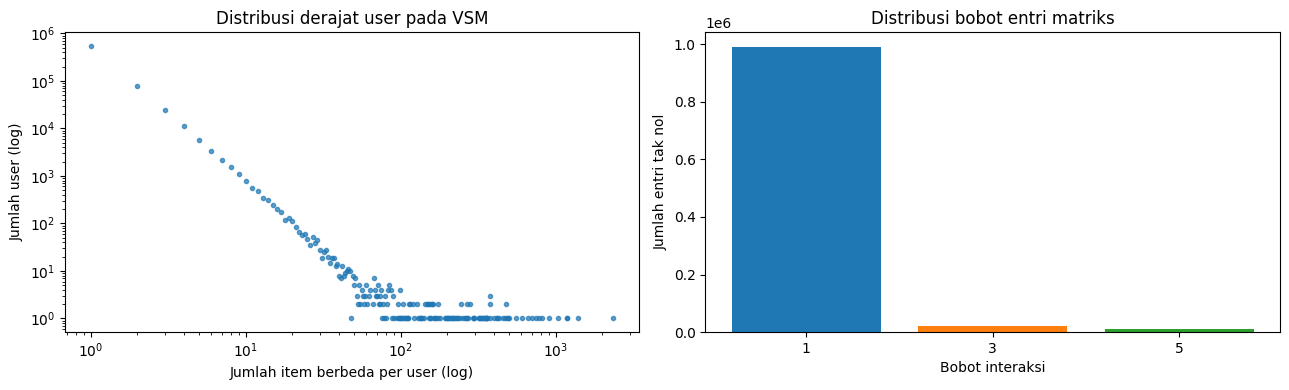

In [ ]:
# distribusi

import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(13, 4))

v, c = np.unique(items_per_user, return_counts=True)
ax[0].loglog(v, c, ".", alpha=.7)
ax[0].set_xlabel("Jumlah item berbeda per user (log)")
ax[0].set_ylabel("Jumlah user (log)")
ax[0].set_title("Distribusi derajat user pada VSM")

ax[1].bar([str(int(b)) for b in bobot], jumlah, color=["tab:blue", "tab:orange", "tab:green"][:len(bobot)])
ax[1].set_xlabel("Bobot interaksi")
ax[1].set_ylabel("Jumlah entri tak nol")
ax[1].set_title("Distribusi bobot entri matriks")
plt.tight_layout()
plt.show()

Item paling populer: 5411 | jumlah user: 1621
Graf bipartit sampel: simpul = 25 | sisi = 37
Proyeksi user-user  : simpul = 15 | sisi = 105 | density = 1.0


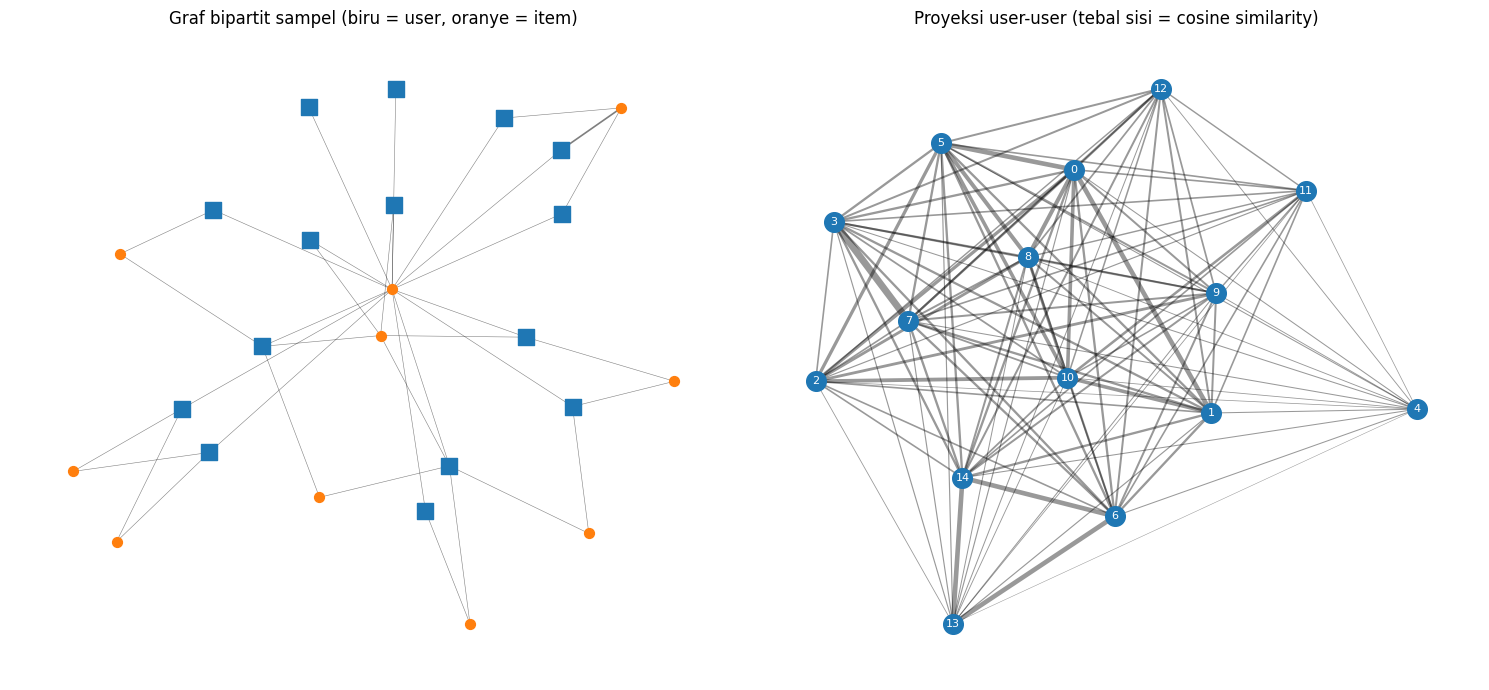

In [ ]:
# plot networkx pada sampel user

import networkx as nx
from sklearn.metrics.pairwise import cosine_similarity

rng = np.random.default_rng(42)
star = int(users_per_item.argmax())                         
users_star = Xc.indices[Xc.indptr[star]:Xc.indptr[star + 1]]
cand = users_star[(items_per_user[users_star] >= 3) & (items_per_user[users_star] <= 30)]
sample = rng.choice(cand, size=min(15, len(cand)), replace=False)
print("Item paling populer:", int(item_ids[star]), "| jumlah user:", len(users_star))

sub = X[sample]
shared = np.where(np.diff(sub.tocsc().indptr) >= 2)[0]      
sub = sub[:, shared].tocoo()

B = nx.Graph()
un = [("u", int(user_ids[u])) for u in sample]
inn = [("i", int(item_ids[j])) for j in shared]
B.add_nodes_from(un, bipartite=0)
B.add_nodes_from(inn, bipartite=1)
for r, c, w in zip(sub.row, sub.col, sub.data):
    B.add_edge(un[r], inn[c], weight=float(w))

S = cosine_similarity(X[sample])
P = nx.Graph()
P.add_nodes_from(range(len(sample)))
for a in range(len(sample)):
    for b in range(a + 1, len(sample)):
        if S[a, b] > 0:
            P.add_edge(a, b, weight=float(S[a, b]))

print("Graf bipartit sampel: simpul =", B.number_of_nodes(), "| sisi =", B.number_of_edges())
print("Proyeksi user-user  : simpul =", P.number_of_nodes(), "| sisi =", P.number_of_edges(),
      "| density =", round(nx.density(P), 3))

fig, ax = plt.subplots(1, 2, figsize=(15, 7))

pos = nx.spring_layout(B, seed=42)
nx.draw_networkx_nodes(B, pos, nodelist=un, node_shape="s", node_color="tab:blue", node_size=120, ax=ax[0])
nx.draw_networkx_nodes(B, pos, nodelist=inn, node_color="tab:orange", node_size=50, ax=ax[0])
nx.draw_networkx_edges(B, pos, width=[B[a][b]["weight"] * 0.4 for a, b in B.edges], alpha=.5, ax=ax[0])
ax[0].set_title("Graf bipartit sampel (biru = user, oranye = item)")
ax[0].axis("off")

posP = nx.spring_layout(P, seed=42)
nx.draw_networkx_nodes(P, posP, node_color="tab:blue", node_size=200, ax=ax[1])
nx.draw_networkx_edges(P, posP, width=[P[a][b]["weight"] * 5 for a, b in P.edges], alpha=.4, ax=ax[1])
nx.draw_networkx_labels(P, posP, labels={n: str(n) for n in P.nodes}, font_color="white", font_size=8, ax=ax[1])
ax[1].set_title("Proyeksi user-user (tebal sisi = cosine similarity)")
ax[1].axis("off")

plt.tight_layout()
plt.show()

**Penjelasan hasil (2.1.4): VSM simpul User**

**1. Dari relasi menjadi pasangan (user, item).**
Query agregasi menghasilkan **1.021.957 pasangan unik (user, item)** dari 1.312.675 relasi. Selisihnya, **290.718 relasi (±22,2%)**, adalah interaksi berulang pada pasangan yang sama (rata-rata 1,28 relasi per pasangan). Multigraf pada Neo4j diringkas menjadi graf bipartit sederhana berbobot, dengan bobot interaksi tertinggi per pasangan.

**2. Dimensi dan shape.**
Matriks VSM berukuran **(677.687 × 170.744)**: setiap user adalah satu vektor berdimensi **170.744** (satu sumbu per item), dan ada 677.687 vektor. Tipe data `float32` dalam format sparse CSR.

**3. Sangat jarang (*sparse*).**

| Ukuran | Nilai |
|---|---|
| Entri tak nol (nnz) | 1.021.957 |
| Density | 0,000883% |
| Sparsity | 99,9991% |
| Memori jika dense (float32) | 462,8 GB |
| Memori sparse CSR | 10,9 MB |

Representasi sparse menghemat memori sekitar **42.000 kali lipat**. Matriks dense tidak mungkin disimpan di komputer biasa, sehingga format sparse wajib dipakai.

**4. Distribusi jumlah item per user (heavy-tailed).**

| Statistik | Nilai |
|---|---|
| Rata-rata | 1,51 item per user |
| Median | 1 item |
| Tepat 1 item | **80,31%** (± 544 ribu user) |
| ≥ 2 item | 19,69% |
| ≥ 5 item | 2,71% |
| Persentil 90 / 95 / 99 / 99,9 | 2 / 3 / 8 / 26 item |
| Maksimum | 2.345 item |

Pada plot log-log (kiri), titik-titik membentuk garis yang hampir lurus menurun. Itu ciri distribusi **berekor panjang (mirip power law)**: mayoritas besar user hanya berinteraksi dengan satu item, sementara sangat sedikit user yang berinteraksi dengan ratusan sampai ribuan item (kemungkinan pengguna sangat aktif atau aktivitas otomatis).

**5. Distribusi bobot sangat timpang.**
Bobot 1 (hanya `view`) sebanyak 992.028 entri (97,07%), bobot 3 (`addtocart`, tanpa beli) 19.837 entri (1,94%), dan bobot 5 (`BOUGHT`) 10.092 entri (0,99%). Sinyal minat yang kuat (keranjang dan pembelian) hanya sekitar 3% dari seluruh entri. Jumlah pasangan dengan pembelian (10.092) sedikit lebih kecil daripada relasi `BOUGHT` (10.653) karena sebagian pembelian berulang pada pasangan yang sama.

**6. Norma vektor.**
Rata-rata norma L2 vektor user adalah 1,217. Nilainya dekat 1 karena kebanyakan user hanya punya satu entri berbobot 1 (norma = 1). Norma bervariasi mengikuti jumlah dan bobot interaksi, sehingga untuk menghitung kemiripan perlu normalisasi (misalnya **cosine similarity**).

**7. Contoh vektor.**
User `901216` direpresentasikan sebagai vektor berdimensi 170.744 yang hanya memiliki **5 entri tak nol** (semua bobot 1, hanya `view`), sedangkan 170.739 elemen lainnya bernilai 0.

**8. Visualisasi networkx.**
- **Graf bipartit sampel** (kiri): item paling populer (ID 5411, dilihat oleh 1.621 user) menjadi **hub** di tengah graf, dan sebagian besar user sampel terhubung ke item tersebut. Item lain hanya dipakai oleh sedikit user. Sampel terdiri atas 25 simpul (15 user dan 10 item bersama) dengan 37 sisi.
- **Proyeksi user–user** (kanan): 15 simpul dengan 105 sisi dan density 1,0, yaitu **graf lengkap** (C(15,2) = 105). Ini terjadi karena seluruh user sampel punya item populer yang sama, sehingga cosine similarity antar pasangan selalu lebih dari 0. Ketebalan sisi menunjukkan perbedaan kemiripan: pasangan yang berbagi lebih banyak item (dengan bobot lebih besar) tampil lebih tebal. Sampel sengaja berpusat pada satu item populer, jadi kepadatan 1,0 tidak mewakili seluruh graf.

**9. Implikasi.**
- **Cold start:** 80,31% user hanya punya satu item, sehingga hanya bisa mirip dengan user yang berinteraksi dengan item yang sama. Hanya sekitar 19,7% user (± 133 ribu) yang punya cukup interaksi untuk perbandingan yang bermakna.
- Item populer bertindak sebagai **hub** yang menghubungkan banyak user, sehingga kemiripan antar user mudah didominasi oleh item populer.
- Ukuran dimensi (170.744) memang besar, tetapi karena sparsity ekstrem, biaya penyimpanan dan komputasi tetap kecil jika memakai operasi sparse.

### 2.1.5 Vector Space Modelling (VSM) simpul Item

**Konsep.** Pada VSM untuk Item, setiap simpul `Item` direpresentasikan sebagai **sebuah vektor** dalam ruang yang sumbunya adalah seluruh simpul `Visitor` (user). Ini adalah sisi "kebalikan" dari no. 4:

- **Dimensi vektor** = jumlah user unik pada graf training.
- **Isi vektor** (nilai pada sumbu user *u*) = bobot interaksi user *u* terhadap item tersebut (1 = `view`, 3 = `addtocart`, 5 = `BOUGHT`), dan 0 jika tidak ada interaksi.
- Seluruh vektor item disusun sebagai baris-baris **matriks item–user** `Xᵀ`, yaitu **transpos** dari matriks user–item `X` pada no. 4.

Secara graf, vektor sebuah item dibentuk dari **relasi masuk** ke simpul item tersebut, sedangkan vektor user (no. 4) dibentuk dari **relasi keluar**. Karena itu data sumbernya sama dengan no. 4 (agregasi per pasangan user–item, dengan pembobotan 1/3/5), sehingga tidak perlu query ulang ke Neo4j. Query yang setara dari sisi item adalah:

```cypher
MATCH (i:Item)<-[r]-(v:Visitor)
RETURN i.itemId AS item, v.visitorId AS visitor, count(r) AS jumlah_relasi
```
(`<-[r]-` adalah pola relasi masuk ke item. Hasil per pasangan identik dengan agregasi pada no. 4.)

Matriks disimpan sebagai **sparse CSR** karena sangat jarang.

**Langkah analisis karakteristik:** dimensi dan shape, density dan sparsity, ukuran memori, distribusi jumlah user per item, tingkat konsentrasi popularitas (*long tail*), item terpopuler, norma vektor, serta visualisasi `networkx` pada sampel item (graf bipartit item–user dan proyeksi item–item berbasis cosine similarity).

In [ ]:
# bangun matriks VSM item–user

Xt = X.T.tocsr()                                
n_items, n_users = Xt.shape
print("Shape matriks VSM item (item x user):", Xt.shape)
print("Tipe:", type(Xt).__name__, "| dtype:", Xt.dtype)

Shape matriks VSM item (item x user): (170744, 677687)
Tipe: csr_matrix | dtype: float32


In [ ]:
# karakteristik VSM item

upi = np.diff(Xt.indptr)                         
ipu = np.diff(X.indptr)                         
nnz = Xt.nnz
density = nnz / (n_items * n_users)
dense_gb = n_items * n_users * 4 / 1e9
sparse_mb = (Xt.data.nbytes + Xt.indices.nbytes + Xt.indptr.nbytes) / 1e6

norms_i = np.sqrt(np.asarray(Xt.multiply(Xt).sum(axis=1)).ravel())     
pop_score = np.asarray(Xt.sum(axis=1)).ravel()                        

bm = Xt.copy()
bm.data = (bm.data == W_BUY).astype(np.int32)
buyers = np.asarray(bm.sum(axis=1)).ravel()                          

ringkas = pd.Series({
    "Jumlah vektor (item)": n_items,
    "Dimensi tiap vektor (user)": n_users,
    "Shape": str(Xt.shape),
    "Entri tak nol (nnz)": nnz,
    "Density": f"{density:.6%}",
    "Sparsity": f"{1 - density:.4%}",
    "Ukuran dense (float32)": f"{dense_gb:,.1f} GB",
    "Ukuran sparse CSR": f"{sparse_mb:,.1f} MB",
    "Rata-rata user per item": round(upi.mean(), 3),
    "Median user per item": int(np.median(upi)),
    "Maks user per item": int(upi.max()),
    "Item dengan tepat 1 user": f"{(upi == 1).mean():.2%}",
    "Item dengan >= 2 user": f"{(upi >= 2).mean():.2%}",
    "Item dengan >= 5 user": f"{(upi >= 5).mean():.2%}",
    "Item dengan >= 10 user": f"{(upi >= 10).mean():.2%}",
    "Item yang pernah dibeli": f"{(buyers > 0).sum():,} ({(buyers > 0).mean():.2%})",
    "Norma L2 rata-rata": round(norms_i.mean(), 3),
})
display(ringkas.to_frame("Nilai"))

print("Persentil user per item:")
print(pd.Series(upi).quantile([.5, .75, .9, .95, .99, .999]).to_string())

srt = np.sort(upi)[::-1]
cum = np.cumsum(srt) / srt.sum()
display(pd.DataFrame({
    "Item teratas": ["1%", "5%", "10%", "20%"],
    "Porsi seluruh interaksi": [f"{cum[int(np.ceil(p * n_items)) - 1]:.2%}" for p in (.01, .05, .10, .20)],
}))

,Nilai
Jumlah vektor (item),170744
Dimensi tiap vektor (user),677687
Shape,"(170744, 677687)"
Entri tak nol (nnz),1021957
Density,0.000883%
Sparsity,99.9991%
Ukuran dense (float32),462.8 GB
Ukuran sparse CSR,8.9 MB
Rata-rata user per item,5.985
Median user per item,2


Persentil user per item:
0.500      2.0
0.750      5.0
0.900     13.0
0.950     23.0
0.990     63.0
0.999    178.0


,Item teratas,Porsi seluruh interaksi
0,1%,18.91%
1,5%,42.51%
2,10%,56.62%
3,20%,71.97%


In [ ]:
# 10 item terpopuler dan contoh vektor item

top = (pd.DataFrame({"itemId": item_ids, "jumlah_user": upi,
                     "skor_bobot": pop_score, "jumlah_pembeli": buyers})
         .sort_values("jumlah_user", ascending=False).head(10).reset_index(drop=True))
display(top)

i = int(np.argmax(upi == 5))                    
row = Xt[i]
print("Item (itemId):", item_ids[i])
print("Dimensi vektor:", row.shape[1], "| entri tak nol:", row.nnz)
print({int(user_ids[j]): float(w) for j, w in zip(row.indices, row.data)})

,itemId,jumlah_user,skor_bobot,jumlah_pembeli
0,5411,1621,1633.0,0
1,309778,790,872.0,10
2,370653,762,762.0,0
3,298009,688,688.0,0
4,335975,665,665.0,0
5,257040,605,699.0,12
6,96924,593,593.0,0
7,354233,564,582.0,0
8,461686,509,813.0,50
9,441668,503,539.0,5


Item (itemId): 386527
Dimensi vektor: 677687 | entri tak nol: 5
{76757: 5.0, 765630: 1.0, 759369: 1.0, 1313381: 1.0, 1301181: 1.0}


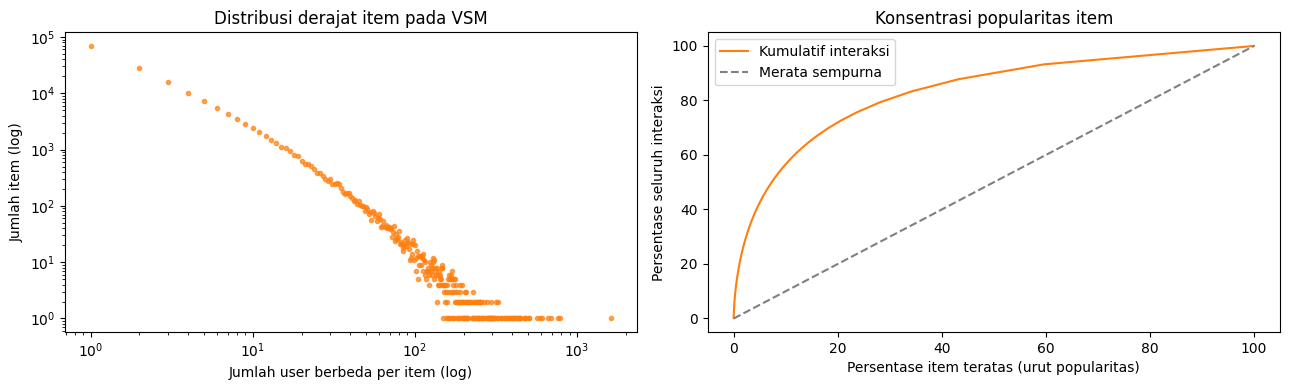

In [ ]:
# distribusi

fig, ax = plt.subplots(1, 2, figsize=(13, 4))

v, c = np.unique(upi, return_counts=True)
ax[0].loglog(v, c, ".", alpha=.7, color="tab:orange")
ax[0].set_xlabel("Jumlah user berbeda per item (log)")
ax[0].set_ylabel("Jumlah item (log)")
ax[0].set_title("Distribusi derajat item pada VSM")

x = np.arange(1, n_items + 1) / n_items * 100
ax[1].plot(x, cum * 100, color="tab:orange", label="Kumulatif interaksi")
ax[1].plot([0, 100], [0, 100], "--", color="gray", label="Merata sempurna")
ax[1].set_xlabel("Persentase item teratas (urut popularitas)")
ax[1].set_ylabel("Persentase seluruh interaksi")
ax[1].set_title("Konsentrasi popularitas item")
ax[1].legend()
plt.tight_layout()
plt.show()

User paling aktif: 1150086 | jumlah item: 2345
Graf bipartit sampel: simpul = 22 | sisi = 31
Proyeksi item-item  : simpul = 15 | sisi = 105 | density = 1.0


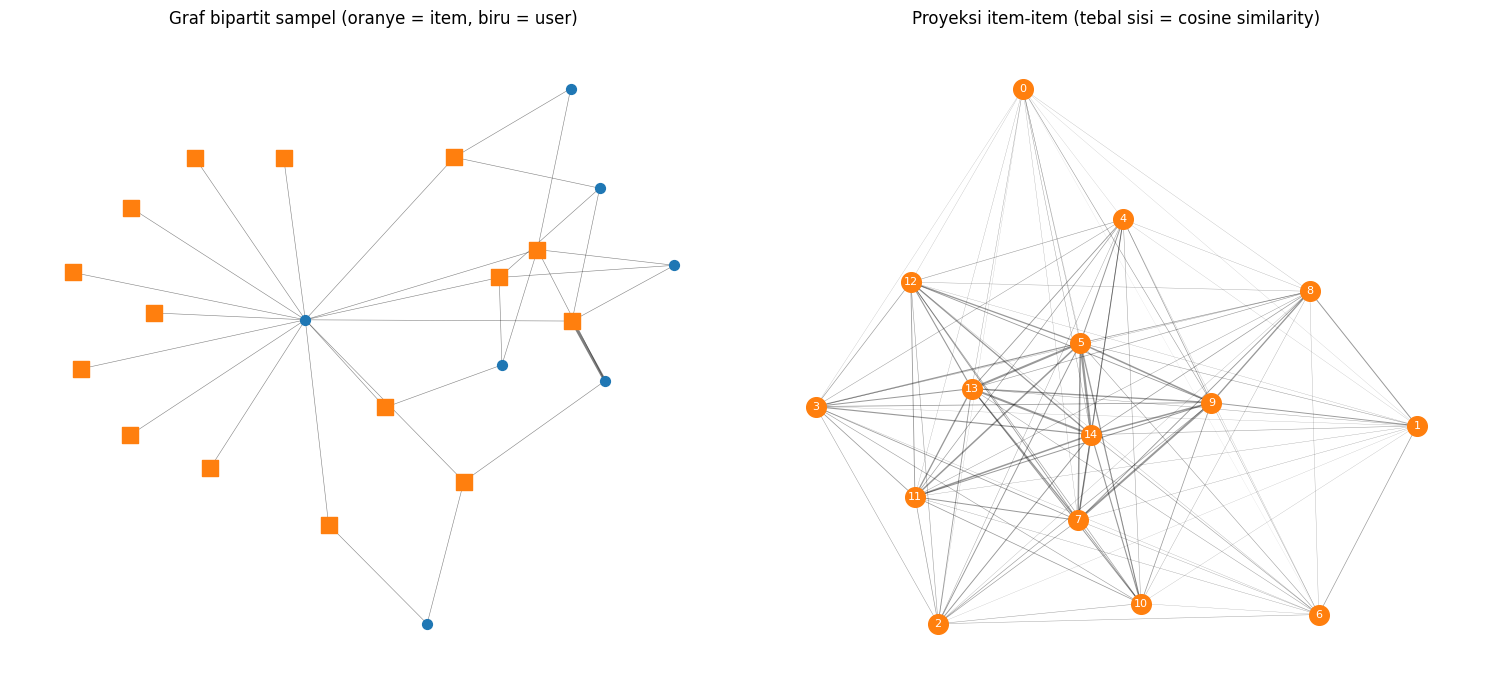

In [ ]:
# plot networkx pada sampel item

import networkx as nx
from sklearn.metrics.pairwise import cosine_similarity

rng = np.random.default_rng(42)
star_u = int(ipu.argmax())                                      
items_star = X.indices[X.indptr[star_u]:X.indptr[star_u + 1]]
cand = items_star[(upi[items_star] >= 3) & (upi[items_star] <= 30)]
sample = rng.choice(cand, size=min(15, len(cand)), replace=False)
print("User paling aktif:", int(user_ids[star_u]), "| jumlah item:", len(items_star))

sub = Xt[sample]
shared = np.where(np.diff(sub.tocsc().indptr) >= 2)[0]            
sub = sub[:, shared].tocoo()

B = nx.Graph()
inn = [("i", int(item_ids[j])) for j in sample]
un = [("u", int(user_ids[u])) for u in shared]
B.add_nodes_from(inn, bipartite=0)
B.add_nodes_from(un, bipartite=1)
for r, c, w in zip(sub.row, sub.col, sub.data):
    B.add_edge(inn[r], un[c], weight=float(w))

S = cosine_similarity(Xt[sample])
P = nx.Graph()
P.add_nodes_from(range(len(sample)))
for a in range(len(sample)):
    for b in range(a + 1, len(sample)):
        if S[a, b] > 0:
            P.add_edge(a, b, weight=float(S[a, b]))

print("Graf bipartit sampel: simpul =", B.number_of_nodes(), "| sisi =", B.number_of_edges())
print("Proyeksi item-item  : simpul =", P.number_of_nodes(), "| sisi =", P.number_of_edges(),
      "| density =", round(nx.density(P), 3))

fig, ax = plt.subplots(1, 2, figsize=(15, 7))

pos = nx.spring_layout(B, seed=42)
nx.draw_networkx_nodes(B, pos, nodelist=inn, node_shape="s", node_color="tab:orange", node_size=120, ax=ax[0])
nx.draw_networkx_nodes(B, pos, nodelist=un, node_color="tab:blue", node_size=50, ax=ax[0])
nx.draw_networkx_edges(B, pos, width=[B[a][b]["weight"] * 0.4 for a, b in B.edges], alpha=.5, ax=ax[0])
ax[0].set_title("Graf bipartit sampel (oranye = item, biru = user)")
ax[0].axis("off")

posP = nx.spring_layout(P, seed=42)
nx.draw_networkx_nodes(P, posP, node_color="tab:orange", node_size=200, ax=ax[1])
nx.draw_networkx_edges(P, posP, width=[P[a][b]["weight"] * 5 for a, b in P.edges], alpha=.4, ax=ax[1])
nx.draw_networkx_labels(P, posP, labels={n: str(n) for n in P.nodes}, font_color="white", font_size=8, ax=ax[1])
ax[1].set_title("Proyeksi item-item (tebal sisi = cosine similarity)")
ax[1].axis("off")

plt.tight_layout()
plt.show()

**Penjelasan hasil (2.1.5): VSM simpul Item**

**1. Dimensi dan shape.**
Matriks VSM item berukuran **(170.744 × 677.687)**: ada 170.744 vektor item, masing-masing berdimensi **677.687** (satu sumbu per user). Ini adalah transpos matriks user–item pada no. 4, sehingga jumlah entri tak nol (1.021.957), density (0,000883%), dan sparsity (99,9991%) **identik**. Memori dense tetap 462,8 GB, sedangkan sparse CSR hanya **8,9 MB**. Ukuran ini lebih kecil daripada matriks user (10,9 MB) karena CSR menyimpan satu penunjuk baris per vektor, dan jumlah baris item (170.744) jauh lebih sedikit daripada user (677.687).

**2. Distribusi jumlah user per item.**

| Statistik | Nilai |
|---|---|
| Rata-rata | 5,99 user per item |
| Median | 2 user |
| Tepat 1 user | 40,55% |
| ≥ 2 user | 59,45% |
| ≥ 5 user | 27,82% |
| ≥ 10 user | 14,03% |
| Persentil 90 / 95 / 99 / 99,9 | 13 / 23 / 63 / 178 user |
| Maksimum | 1.621 user |

Plot log-log (kiri) berupa garis menurun yang hampir lurus, yaitu distribusi **berekor panjang (mirip power law)**: banyak item hanya dipakai sedikit user, dan sedikit item dipakai banyak user. Satu titik di ujung kanan (± 1.600 user) adalah item paling populer.

**3. Konsentrasi popularitas (*long tail*).**

| Item teratas | Porsi seluruh interaksi |
|---|---|
| 1% | 18,91% |
| 5% | 42,51% |
| 10% | 56,62% |
| 20% | 71,97% |

Kurva kumulatif (kanan) melengkung jauh di atas garis diagonal "merata sempurna", artinya interaksi terkonsentrasi pada item populer. Konsentrasinya cukup kuat tetapi tidak seekstrem aturan 80/20: 20% item teratas memegang sekitar 72% interaksi.

**4. Sinyal pembelian pada level item.**
Hanya **6.673 item (3,91%)** yang pernah dibeli, sehingga 96,09% item tidak pernah dibeli pada periode training. Item terpopuler (ID 5411, 1.621 user) bahkan **tidak pernah dibeli (0 pembeli)**: popularitas lihat tidak sama dengan popularitas beli. Sebaliknya, item `461686` dilihat 509 user dan dibeli 50 user.

**5. Norma vektor.**
Rata-rata norma L2 vektor item adalah 2,135, lebih tinggi daripada vektor user (1,217) karena vektor item rata-rata memiliki lebih banyak entri tak nol (5,99 dibanding 1,51).

**6. Contoh vektor.**
Item `386527` berupa vektor berdimensi 677.687 dengan **5 entri tak nol**: satu user membeli (bobot 5) dan empat user hanya melihat (bobot 1).

**7. Visualisasi networkx.**
- **Graf bipartit sampel** (kiri): user paling aktif (ID 1150086, 2.345 item) menjadi **hub** yang terhubung ke seluruh item sampel. Sampel terdiri atas 22 simpul (15 item dan 7 user bersama) dengan 31 sisi. User lain hanya menghubungkan 2 sampai 3 item. Satu sisi yang jauh lebih tebal menunjukkan interaksi berbobot besar (pembelian).
- **Proyeksi item–item** (kanan): 15 simpul dengan 105 sisi dan density 1,0, yaitu **graf lengkap**, karena semua item sampel dipakai oleh hub user yang sama. Perbedaan ketebalan sisi menunjukkan perbedaan kemiripan. Sisi tipis adalah pasangan item yang hanya mirip karena sama-sama dipakai hub user, sedangkan sisi tebal adalah pasangan yang berbagi lebih banyak user. Hal ini menunjukkan **user yang sangat aktif dapat menciptakan kemiripan semu** antar banyak item.

**8. Perbandingan awal dengan VSM user (no. 4).**
Vektor item jauh lebih "padat informasi": median 2 user per item (user: 1 item per user), 59,45% item punya ≥ 2 user (user: 19,69% punya ≥ 2 item), dan 27,82% item punya ≥ 5 user (user: 2,71%). Jumlah vektor item (170.744) juga hanya sekitar seperempat jumlah vektor user.

### 2.1.6 proyeksi mana yang lebih baik?

In [ ]:
# bukti kuantitatif

import time

B = X.copy()
B.data[:] = 1.0                                 
Bt = B.T.tocsr()
ipu = np.diff(B.indptr).astype(np.int64)        
upi = np.diff(Bt.indptr).astype(np.int64)      

cov_user = ((B @ (upi >= 2).astype(np.float32)) > 0).mean()   
cov_item = ((Bt @ (ipu >= 2).astype(np.float32)) > 0).mean()   
print(f"Cakupan proyeksi User-User : {cov_user:.2%} user punya >= 1 tetangga")
print(f"Cakupan proyeksi Item-Item : {cov_item:.2%} item punya >= 1 tetangga")

def proyeksi(M, nama, limit=2e8):
    """M: matriks biner (simpul x dimensi). Proyeksi = M @ M.T (jumlah tetangga bersama)."""
    n_node = M.shape[0]
    d_dim = np.diff(M.tocsc().indptr).astype(np.int64)
    bound = int((d_dim * (d_dim - 1)).sum())     
    out = {"Proyeksi": nama, "Simpul": n_node,
           "Matriks similarity penuh (sel)": f"{n_node ** 2:.3e}",
           "Batas atas entri non-diagonal": bound}
    if bound > limit:
        out["Status"] = "dilewati (terlalu besar)"
        return out
    t0 = time.perf_counter()
    C = (M @ M.T).tocsr()
    dt = time.perf_counter() - t0
    deg = np.diff(C.indptr) - 1                 
    out.update({
        "Status": "dihitung",
        "Sisi nyata (tak berarah)": int(deg.sum() // 2),
        "Density": f"{deg.sum() / (n_node * (n_node - 1)):.6%}",
        "Rata-rata derajat": round(deg.mean(), 2),
        "Median derajat": int(np.median(deg)),
        "Maks derajat": int(deg.max()),
        "Simpul terisolasi": f"{(deg == 0).mean():.2%}",
        "Memori hasil (MB)": round((C.data.nbytes + C.indices.nbytes + C.indptr.nbytes) / 1e6, 1),
        "Waktu hitung (detik)": round(dt, 2),
    })
    return out

hasil = pd.DataFrame([proyeksi(B, "User-User"), proyeksi(Bt, "Item-Item")]).set_index("Proyeksi").T
display(hasil)

Cakupan proyeksi User-User : 93.47% user punya >= 1 tetangga
Cakupan proyeksi Item-Item : 60.80% item punya >= 1 tetangga


Proyeksi,User-User,Item-Item
Simpul,677687,170744
Matriks similarity penuh (sel),4.593e+11,2.915e+10
Batas atas entri non-diagonal,45664962,25673558
Status,dihitung,dihitung
Sisi nyata (tak berarah),22145218,11678422
Density,0.009644%,0.080117%
Rata-rata derajat,65.36,136.79
Median derajat,19,1
Maks derajat,67211,12670
Simpul terisolasi,6.53%,39.20%


### 2.1.6 Perbandingan proyeksi User–User dan Item–Item

Kedua proyeksi dibangun dari matriks biner (ada atau tidaknya interaksi) sebagai `M · Mᵀ`, sehingga sisi menghubungkan dua simpul yang berbagi minimal satu tetangga (dua user berbagi item, atau dua item berbagi user).

| Aspek | Proyeksi User–User | Proyeksi Item–Item |
|---|---|---|
| Jumlah simpul | 677.687 | 170.744 |
| Matriks similarity penuh (sel) | 4,593 × 10¹¹ | 2,915 × 10¹⁰ |
| Sisi nyata (tak berarah) | 22.145.218 | 11.678.422 |
| Density | 0,009644% | 0,080117% |
| Rata-rata derajat | 65,36 | 136,79 |
| **Median derajat** | **19** | **1** |
| Maks derajat | 67.211 | 12.670 |
| **Simpul terisolasi** | **6,53%** | **39,20%** |
| **Cakupan (punya ≥ 1 tetangga)** | **93,47%** | **60,80%** |
| Memori hasil proyeksi | 362,5 MB | 188,9 MB |
| Waktu hitung | 1,55 detik | 1,05 detik |

**1. Efisiensi: proyeksi Item–Item lebih unggul.**
- Matriks similarity penuh proyeksi user sekitar **15,8 kali lebih besar** (4,593 × 10¹¹ dibanding 2,915 × 10¹⁰ sel), karena ukuran tumbuh kuadratik terhadap jumlah simpul.
- Jumlah sisi proyeksi user sekitar **1,9 kali lebih banyak** (22,1 juta dibanding 11,7 juta), memori hasil sekitar 1,9 kali lebih besar (362,5 MB dibanding 188,9 MB), dan waktu hitung sekitar 1,5 kali lebih lama (1,55 detik dibanding 1,05 detik).
- Meski lebih mahal, proyeksi user **masih sangat ringan secara absolut** (di bawah 2 detik dan kurang dari 400 MB) berkat representasi sparse.

**2. Efektivitas: proyeksi User–User lebih unggul.**
- **Cakupan:** 93,47% user punya minimal satu tetangga, sedangkan pada item hanya 60,80%. Sebanyak **39,20% item terisolasi** (± 67 ribu item), artinya kemiripannya tidak dapat dihitung sama sekali.
- **Median derajat** user adalah 19, sedangkan item hanya **1**: separuh item punya paling banyak satu tetangga. Rata-rata derajat item (136,79) tampak besar, tetapi itu ditarik oleh segelintir item populer (maks 12.670), bukan keadaan item pada umumnya.
- Penyebabnya: dua item hanya terhubung bila ada **user yang berinteraksi dengan keduanya**. Karena 80,31% user hanya punya satu item, item yang hanya dipakai oleh user seperti itu tidak punya tetangga. Sebaliknya dua user terhubung bila berbagi satu item saja, dan banyak item (59,45%) dipakai oleh ≥ 2 user.
- **Kekuatan hubungan:** pasangan item lebih sering berbagi lebih dari satu user. Batas atas pasangan (45,66 juta untuk user, 25,67 juta untuk item) dibandingkan dengan hubungan nyata (44,29 juta dan 23,36 juta entri berarah) menunjukkan sekitar 3,0% pasangan user dan sekitar 9,0% pasangan item yang berbagi lebih dari satu tetangga. Jadi kemiripan item yang ada cenderung lebih kuat, tetapi lebih sedikit item yang memilikinya.

**3. Risiko pada kedua proyeksi.**
- **Hub:** derajat maksimum user mencapai 67.211 (± 9,9% dari seluruh user), dan item 12.670 (± 7,4%). Hub membuat banyak sisi kemiripan semu (terlihat pada plot sampel yang berbentuk graf lengkap).
- **Kemiripan bernilai sama:** user yang hanya punya satu item memiliki vektor yang identik dengan user lain yang memilih item yang sama, sehingga muncul banyak nilai similarity yang sama (*tie*).
- Mitigasi: gunakan **cosine similarity** pada vektor berbobot (bukan sekadar jumlah tetangga bersama), pilih simpul acuan yang punya cukup interaksi, dan simpan hanya **top-k tetangga** per simpul.

**4. Kesimpulan.**
Terdapat *trade-off*: proyeksi Item–Item lebih **efisien**, sedangkan proyeksi User–User lebih **efektif**. Proyeksi **User–User dipilih** untuk perhitungan similarity berikutnya (no. 7 dan 8) karena:
1. kesenjangan efektivitas besar (cakupan 93,47% dibanding 60,80%, median derajat 19 dibanding 1), sedangkan selisih efisiensinya tidak menghalangi (kurang dari 2 detik dan kurang dari 400 MB);
2. similarity hanya ditulis ke graf sebagai top-k tetangga, sehingga biaya penulisan tidak bergantung pada ukuran penuh proyeksi;
3. tahap Analytics (2.2) menggunakan KNN berbasis user, sehingga kemiripan antar-user langsung dibutuhkan.

Proyeksi Item–Item tetap berguna sebagai pelengkap (misalnya untuk item populer yang punya banyak tetangga), tetapi tidak dapat melayani 39,20% item yang terisolasi.

### 2.1.7 Perhitungan similarity pada graf proyeksi User–User

Berdasarkan analisis no. 6, proyeksi **User–User** dipakai. Kemiripan dua user dihitung dengan **cosine similarity** pada vektor VSM berbobot (bobot 1 = `view`, 3 = `addtocart`, 5 = `BOUGHT`):

$$\cos(u, v) = \frac{u \cdot v}{\lVert u \rVert \, \lVert v \rVert}$$

Nilainya berada pada rentang 0 sampai 1 (bobot tidak negatif): 0 berarti tidak ada item yang sama, dan 1 berarti arah vektor identik. Cosine dipilih karena menormalkan panjang vektor, sehingga user dengan banyak interaksi tidak otomatis dianggap lebih mirip.

**Record acuan.** Dipilih satu user secara acak dan *reproducible* (`numpy.random.default_rng(42)`) dari user yang punya 5 sampai 30 item berbeda, agar vektornya cukup informatif (user dengan satu item menghasilkan banyak nilai similarity yang sama).

**Alur kerja:**
1. (Python) menghitung cosine similarity user acuan terhadap seluruh user lain, lalu mengambil **5 user dengan similarity tertinggi**.
2. **(b)** (Python + Cypher) menuliskan kembali nilai similarity ke graf sebagai relasi `(:Visitor)-[:SIMILAR_TO {score, rank, method}]->(:Visitor)`. `MERGE` dipakai agar penulisan ulang tidak menggandakan relasi.
3. **(a)** (Cypher) mengambil 5 record dengan similarity tertinggi dari graf dengan `ORDER BY s.score DESC LIMIT 5`, ditambah bukti item bersama.

In [ ]:
# record acuan, similarity, top-5

from sklearn.metrics.pairwise import cosine_similarity

MODE = "user"          
if MODE == "user":
    V, ids, LABEL, PROP = X, user_ids, "Visitor", "visitorId"
else:
    V, ids, LABEL, PROP = Xt, item_ids, "Item", "itemId"

deg = np.diff(V.indptr)                              

rng = np.random.default_rng(42)
cand = np.where((deg >= 5) & (deg <= 30))[0]
ref = int(rng.choice(cand))
REF_ID = int(ids[ref])
print(f"Record acuan: {LABEL} {REF_ID} | jumlah entri vektor: {deg[ref]} | kandidat acuan: {len(cand):,}")

sim = cosine_similarity(V[ref], V).ravel()
sim[ref] = -1                                           
print("Simpul dengan similarity > 0:", f"{(sim > 0).sum():,}", "dari", f"{len(sim) - 1:,}")

K = 5
top_idx = np.lexsort((np.arange(len(sim)), -sim))[:K]    

bref = V[ref] > 0
top_df = pd.DataFrame({
    "peringkat": range(1, K + 1),
    LABEL + "_id": [int(ids[j]) for j in top_idx],
    "cosine": [round(float(sim[j]), 6) for j in top_idx],
    "entri_acuan": int(deg[ref]),
    "entri_tetangga": [int(deg[j]) for j in top_idx],
    "entri_bersama": [int(bref.multiply(V[j] > 0).nnz) for j in top_idx],
})
display(top_df)

rows = [{"id": int(ids[j]), "score": float(sim[j]), "rank": r + 1} for r, j in enumerate(top_idx)]

Record acuan: Visitor 439698 | jumlah entri vektor: 14 | kandidat acuan: 17,863
Simpul dengan similarity > 0: 1,559 dari 677,686


,peringkat,Visitor_id,cosine,entri_acuan,entri_tetangga,entri_bersama
0,1,534730,0.377964,14,2,2
1,2,974394,0.377964,14,2,2
2,3,1203695,0.377964,14,2,2
3,4,624671,0.358569,14,5,3
4,5,757651,0.322329,14,3,2


In [ ]:
# kondisi graf sebelum menulis similarity

before = run_query("MATCH ()-[s:SIMILAR_TO]->() RETURN count(s) AS jumlah_relasi_similar_to")
display(before)

before_total = run_query("MATCH ()-[r]->() RETURN count(r) AS total_relasi")
display(before_total)

Received notification from DBMS server: <GqlStatusObject gql_status='01N51', status_description='warn: relationship type does not exist. The relationship type `SIMILAR_TO` does not exist in database `neo4j`. Verify that the spelling is correct.', position=<SummaryInputPosition line=1, column=13, offset=12>, raw_classification='UNRECOGNIZED', classification=<NotificationClassification.UNRECOGNIZED: 'UNRECOGNIZED'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'UNRECOGNIZED', '_severity': 'WARNING', '_position': {'offset': 12, 'line': 1, 'column': 13}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: 'MATCH ()-[s:SIMILAR_TO]->() RETURN count(s) AS jumlah_relasi_similar_to'


,jumlah_relasi_similar_to
0,0


,total_relasi
0,1312675


In [ ]:
# (b) tulis similarity kembali ke graf

query_write = """
MATCH (a:__L__ {__P__: $ref})
UNWIND $rows AS row
MATCH (b:__L__ {__P__: row.id})
MERGE (a)-[s:SIMILAR_TO {method: 'cosine'}]->(b)
SET s.score = row.score, s.rank = row.rank
RETURN count(s) AS relasi_ditulis
""".replace("__L__", LABEL).replace("__P__", PROP)

res = driver.execute_query(query_write, ref=REF_ID, rows=rows, database_=DB)
print("Relasi SIMILAR_TO yang ditulis:", res.records[0]["relasi_ditulis"])

after = run_query("MATCH ()-[s:SIMILAR_TO]->() RETURN count(s) AS jumlah_relasi_similar_to")
display(after)

Relasi SIMILAR_TO yang ditulis: 5


,jumlah_relasi_similar_to
0,5


In [ ]:
# (a) Cypher untuk 5 record dengan similarity tertinggi

query_top5 = """
MATCH (a:__L__ {__P__: $ref})-[s:SIMILAR_TO {method: 'cosine'}]->(b:__L__)
RETURN a.__P__ AS acuan, b.__P__ AS tetangga,
       s.score AS similarity, s.rank AS peringkat
ORDER BY s.score DESC, s.rank ASC
LIMIT 5
""".replace("__L__", LABEL).replace("__P__", PROP)

df_top5 = run_query(query_top5, ref=REF_ID)
display(df_top5)

query_bukti = """
MATCH (a:__L__ {__P__: $ref})-[:SIMILAR_TO]->(b:__L__)
MATCH (a)-[:VIEWED|ADDED_TO_CART|BOUGHT]-(x)-[:VIEWED|ADDED_TO_CART|BOUGHT]-(b)
RETURN b.__P__ AS tetangga, count(DISTINCT x) AS jumlah_bersama,
       collect(DISTINCT coalesce(x.itemId, x.visitorId))[..5] AS contoh_bersama
ORDER BY jumlah_bersama DESC
""".replace("__L__", LABEL).replace("__P__", PROP)
display(run_query(query_bukti, ref=REF_ID))

,acuan,tetangga,similarity,peringkat
0,439698,534730,0.377964,1
1,439698,974394,0.377964,2
2,439698,1203695,0.377964,3
3,439698,624671,0.358569,4
4,439698,757651,0.322329,5


,tetangga,jumlah_bersama,contoh_bersama
0,624671,3,"[260957, 279052, 200231]"
1,534730,2,"[260957, 249207]"
2,757651,2,"[279052, 309778]"
3,974394,2,"[279052, 309778]"
4,1203695,2,"[279052, 200231]"


**Penjelasan hasil (2.1.7)**

**1. Record acuan.**
Dipilih `Visitor 439698` (acak, reproducible dengan seed 42) dari **17.863** kandidat user yang punya 5 sampai 30 item berbeda. Vektor acuan memiliki **14 entri tak nol** (14 item berbeda).

**2. Jumlah tetangga.**
Hanya **1.559 dari 677.686** user lain (± 0,23%) yang memiliki similarity lebih dari 0, yaitu user yang berbagi minimal satu item dengan acuan. Sisanya bernilai 0 karena tidak ada item yang sama. Hasil ini sejalan dengan graf yang sangat jarang (*sparse*) pada no. 3 sampai 6: sebagian besar pasangan user tidak punya hubungan sama sekali.

**3. Lima user dengan similarity tertinggi.**

| Peringkat | Visitor | Cosine | Entri tetangga | Item bersama |
|---|---|---|---|---|
| 1 | 534730 | 0,377964 | 2 | 2 |
| 2 | 974394 | 0,377964 | 2 | 2 |
| 3 | 1203695 | 0,377964 | 2 | 2 |
| 4 | 624671 | 0,358569 | 5 | 3 |
| 5 | 757651 | 0,322329 | 3 | 2 |

**4. Cara membaca nilai cosine.**
- Peringkat 1 sampai 3 bernilai **sama persis** (0,377964 = 1/√7). Nilai ini sesuai dengan 2 / (√14 × √2) bila bobot semua entri adalah 1: vektor acuan beranggota 14 item, tetangga beranggota 2 item, dan keduanya berbagi 2 item.
- Peringkat 4 sesuai dengan 3 / (√14 × √5) = 0,358569, yaitu 3 item bersama dengan tetangga beranggota 5 item.
- Peringkat 5 (0,322329) berbeda dari hitungan biner 2 / (√14 × √3) = 0,3086, sehingga ada entri dengan bobot selain 1 (keranjang atau pembelian) pada pasangan ini. Hal ini menunjukkan bobot 1/3/5 memengaruhi hasil.
- Tiga user di peringkat teratas memiliki **nilai yang sama (*tie*)**. Urutan antar mereka ditentukan oleh aturan tie-break (indeks), bukan karena salah satunya lebih mirip.

**5. Cosine tidak sama dengan banyaknya item bersama.**
User peringkat 4 (624671) berbagi **3 item** dengan acuan, paling banyak di antara kelimanya, tetapi berada di peringkat 4 karena ia punya 5 item sehingga 2 item lainnya tidak dimiliki acuan. Sebaliknya tiga user peringkat teratas hanya punya 2 item dan **seluruhnya** ada pada acuan. Cosine menormalkan panjang vektor, sehingga user yang minatnya hampir seluruhnya tercakup oleh acuan dinilai lebih mirip.

**6. Verifikasi struktur di graf.**
Query Cypher pembuktian menunjukkan jumlah item bersama yang sama dengan kolom `entri_bersama`: 624671 berbagi 3 item (260957, 279052, 200231), sedangkan keempat lainnya berbagi 2 item. Item 309778 yang dipakai bersama oleh dua tetangga (757651 dan 974394) adalah salah satu item terpopuler pada data training (790 user), sehingga hubungan melalui item populer seperti ini kurang spesifik dibanding item langka.

**7. Penulisan kembali ke graf (b).**
Sebelum penulisan terdapat **0** relasi `SIMILAR_TO` (total relasi 1.312.675). Setelah penulisan terdapat **5** relasi `SIMILAR_TO`. Query Cypher (a) mengembalikan lima record dengan nilai yang **sama persis** dengan hasil Python, urut dari similarity tertinggi, sehingga nilai berhasil tersimpan di graf tanpa perubahan.

**Catatan:** peringatan DBMS `relationship type SIMILAR_TO does not exist` pada query pertama hanyalah *warning*, bukan error. Peringatan itu muncul karena tipe relasi tersebut memang belum ada sebelum penulisan (hasilnya 0), dan hilang setelah relasi dibuat. Relasi `SIMILAR_TO` bersifat berarah dari user acuan ke tetangga, sedangkan cosine bersifat simetris (nilai yang sama berlaku ke arah sebaliknya), sehingga cukup disimpan satu arah.

### 2.1.8 Kondisi graf sebelum dan sesudah perhitungan similarity

Untuk memperlihatkan perbedaannya, dibandingkan dua kondisi graf di sekitar user acuan `439698` dan lima tetangga teratasnya:

- **Sebelum:** graf hanya berisi relasi interaksi (`VIEWED`, `ADDED_TO_CART`, `BOUGHT`) antara `Visitor` dan `Item`. Kedekatan antar user hanya tersirat melalui item yang sama (dua user dihubungkan oleh path `(Visitor)→(Item)←(Visitor)`), tanpa nilai kemiripan.
- **Sesudah:** ditambahkan relasi `(:Visitor)-[:SIMILAR_TO {score, rank, method}]->(:Visitor)` dari user acuan ke lima tetangganya, sehingga kemiripan menjadi **properti yang tersimpan di graf** dan dapat di-*query* langsung.

Perbandingan dilakukan dengan (1) hitungan relasi per tipe, (2) query Cypher untuk kedua kondisi, dan (3) visualisasi graf (Neo4j Query dan `networkx`).

In [ ]:
# perbandingan jumlah relasi per tipe

rel_now = run_query("MATCH ()-[r]->() RETURN type(r) AS tipe, count(r) AS jumlah ORDER BY jumlah DESC")

sebelum = rel_now[rel_now["tipe"] != "SIMILAR_TO"].set_index("tipe")["jumlah"].rename("sebelum")
sesudah = rel_now.set_index("tipe")["jumlah"].rename("sesudah")
perbandingan = pd.concat([sebelum, sesudah], axis=1).fillna(0).astype(int)
perbandingan.loc["TOTAL"] = perbandingan.sum()

assert perbandingan.loc["TOTAL", "sebelum"] == int(before_total.iloc[0, 0]), "Total sebelum tidak cocok dengan snapshot no. 7"
display(perbandingan)

,sebelum,sesudah
tipe,,
VIEWED,1269759,1269759
ADDED_TO_CART,32263,32263
BOUGHT,10653,10653
SIMILAR_TO,0,5
TOTAL,1312675,1312680


In [ ]:
# Cypher sebelum vs sesudah

NEIGHBORS = [int(ids[j]) for j in top_idx]       

query_before = """
MATCH (a:Visitor {visitorId: $ref})-[:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
      <-[:VIEWED|ADDED_TO_CART|BOUGHT]-(b:Visitor)
WHERE b.visitorId IN $nb
RETURN b.visitorId AS tetangga, count(DISTINCT i) AS item_bersama
ORDER BY item_bersama DESC, tetangga
"""
print("SEBELUM similarity (tidak ada nilai kemiripan di graf):")
display(run_query(query_before, ref=REF_ID, nb=NEIGHBORS))

query_after = """
MATCH (a:Visitor {visitorId: $ref})-[s:SIMILAR_TO]->(b:Visitor)
OPTIONAL MATCH (a)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
               <-[:VIEWED|ADDED_TO_CART|BOUGHT]-(b)
RETURN b.visitorId AS tetangga, count(DISTINCT i) AS item_bersama,
       s.score AS similarity, s.rank AS peringkat
ORDER BY peringkat
"""
print("SESUDAH similarity (nilai kemiripan tersimpan di graf):")
display(run_query(query_after, ref=REF_ID))

SEBELUM similarity (tidak ada nilai kemiripan di graf):


,tetangga,item_bersama
0,624671,3
1,534730,2
2,757651,2
3,974394,2
4,1203695,2


SESUDAH similarity (nilai kemiripan tersimpan di graf):


,tetangga,item_bersama,similarity,peringkat
0,534730,2,0.377964,1
1,974394,2,0.377964,2
2,1203695,2,0.377964,3
3,624671,3,0.358569,4
4,757651,2,0.322329,5


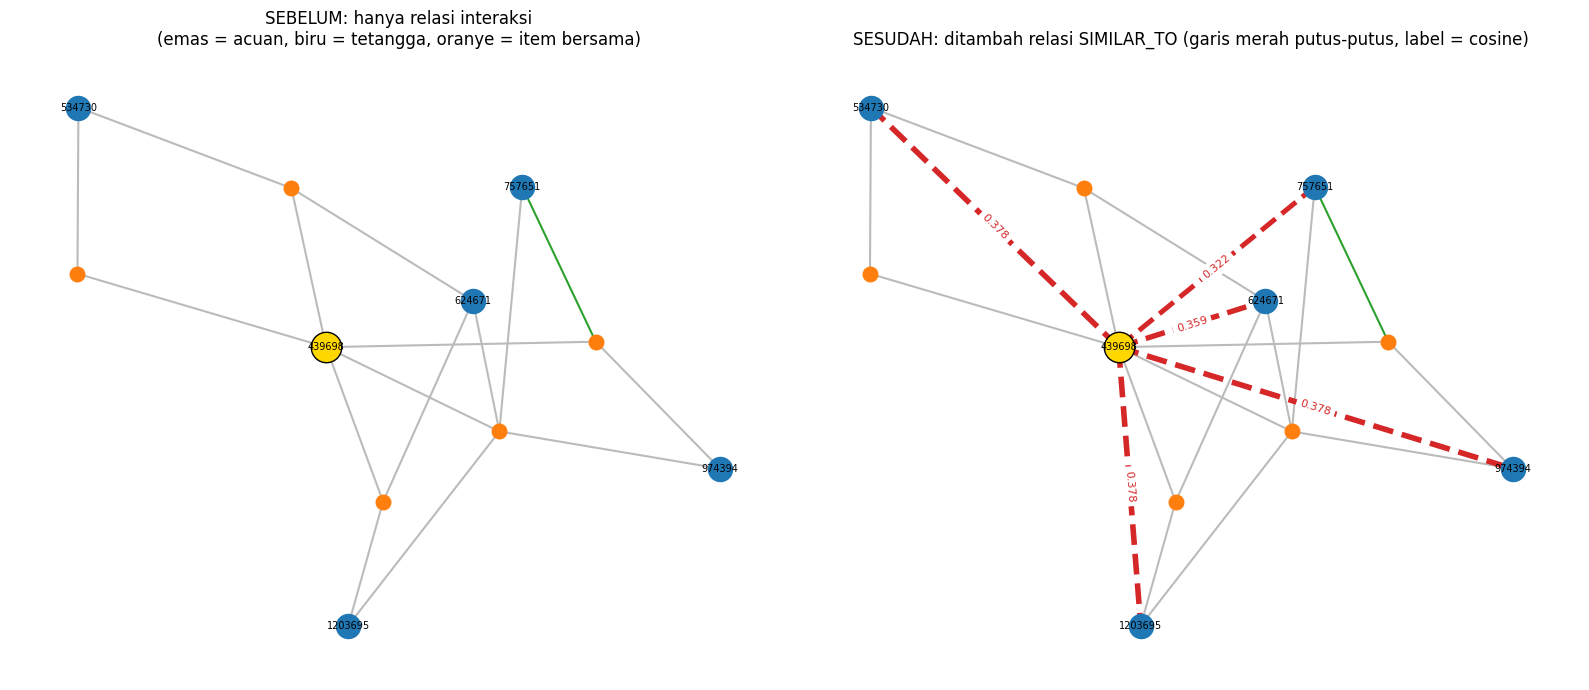

In [ ]:
# visualisasi graf dengan networkx

import networkx as nx
import matplotlib.pyplot as plt

query_sub = """
MATCH (a:Visitor {visitorId: $ref})-[:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
      <-[:VIEWED|ADDED_TO_CART|BOUGHT]-(b:Visitor)
WHERE b.visitorId IN $nb
WITH DISTINCT a, b, i
MATCH (u:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i)
WHERE u = a OR u = b
RETURN DISTINCT u.visitorId AS visitor, i.itemId AS item, type(r) AS tipe
"""
edges = run_query(query_sub, ref=REF_ID, nb=NEIGHBORS)
prio = {"VIEWED": 1, "ADDED_TO_CART": 2, "BOUGHT": 3}
edges["p"] = edges["tipe"].map(prio)
edges = edges.sort_values("p").drop_duplicates(["visitor", "item"], keep="last")   

sim_edges = run_query(query_top5, ref=REF_ID)            

G = nx.Graph()
for r in edges.itertuples():
    G.add_edge(("u", int(r.visitor)), ("i", int(r.item)), tipe=r.tipe)

ref_node = ("u", REF_ID)
nb_nodes = [("u", n) for n in NEIGHBORS]
items_nodes = [n for n in G.nodes if n[0] == "i"]

Gs = nx.DiGraph()
for r in sim_edges.itertuples():
    Gs.add_edge(ref_node, ("u", int(r.tetangga)), score=float(r.similarity))

pos = nx.spring_layout(G, seed=42, k=0.9)
warna = {"VIEWED": "#bbbbbb", "ADDED_TO_CART": "tab:green", "BOUGHT": "black"}

def gambar(ax, dengan_similarity):
    nx.draw_networkx_edges(G, pos, edge_color=[warna[G[a][b]["tipe"]] for a, b in G.edges], width=1.5, ax=ax)
    nx.draw_networkx_nodes(G, pos, nodelist=items_nodes, node_color="tab:orange", node_size=110, ax=ax)
    nx.draw_networkx_nodes(G, pos, nodelist=nb_nodes, node_color="tab:blue", node_size=300, ax=ax)
    nx.draw_networkx_nodes(G, pos, nodelist=[ref_node], node_color="gold", edgecolors="black", node_size=480, ax=ax)
    nx.draw_networkx_labels(G, pos, labels={n: str(n[1]) for n in [ref_node] + nb_nodes}, font_size=7, ax=ax)
    if dengan_similarity:
        nx.draw_networkx_edges(Gs, pos, edge_color="tab:red", style="dashed", arrows=False,
                               width=[1 + d["score"] * 8 for _, _, d in Gs.edges(data=True)], ax=ax)
        nx.draw_networkx_edge_labels(Gs, pos, font_color="tab:red", font_size=8,
                                     edge_labels={(a, b): f"{d['score']:.3f}" for a, b, d in Gs.edges(data=True)}, ax=ax)
    ax.axis("off")

fig, ax = plt.subplots(1, 2, figsize=(16, 7))
gambar(ax[0], False)
ax[0].set_title("SEBELUM: hanya relasi interaksi\n(emas = acuan, biru = tetangga, oranye = item bersama)")
gambar(ax[1], True)
ax[1].set_title("SESUDAH: ditambah relasi SIMILAR_TO (garis merah putus-putus, label = cosine)")
plt.tight_layout()
plt.show()

**Penjelasan hasil (2.1.8)**

**1. Perubahan pada graf hanya penambahan relasi similarity.**

| Tipe relasi | Sebelum | Sesudah |
|---|---|---|
| `VIEWED` | 1.269.759 | 1.269.759 |
| `ADDED_TO_CART` | 32.263 | 32.263 |
| `BOUGHT` | 10.653 | 10.653 |
| `SIMILAR_TO` | 0 | **5** |
| **Total** | **1.312.675** | **1.312.680** |

Seluruh relasi interaksi tidak berubah, dan jumlah simpul tetap 848.431. Satu-satunya perubahan adalah penambahan **5 relasi `SIMILAR_TO`** (± 0,0004% dari seluruh relasi), dari user acuan `439698` ke lima tetangga teratasnya. Panel *Database information* di Neo4j menunjukkan total relasi 1.312.680, dan `SIMILAR_TO` muncul sebagai tipe relasi baru.

**2. Subgraph di sekitar user acuan (hasil Neo4j Query).**
- *Sebelum:* subgraph berisi **11 simpul** (6 `Visitor`: acuan dan 5 tetangga, serta 5 `Item` yang dipakai bersama) dan **20 relasi** (19 `VIEWED` dan 1 `ADDED_TO_CART`). Antar-user tidak ada relasi langsung; kedekatan hanya tersirat lewat jalur dua langkah `(Visitor)→(Item)←(Visitor)`.
- *Sesudah:* simpulnya tetap 11, tetapi relasinya menjadi **25** karena ditambah 5 `SIMILAR_TO` yang menghubungkan acuan langsung ke tiap tetangga.

**3. Perbedaan informasi yang tersedia.**

| Kondisi | Informasi kedekatan antar-user |
|---|---|
| Sebelum | Hanya jumlah item bersama (3, 2, 2, 2, 2), tanpa nilai ternormalisasi dan tanpa urutan yang eksplisit |
| Sesudah | Nilai cosine (0,378; 0,378; 0,378; 0,359; 0,322) dan peringkat tersimpan sebagai properti relasi (`score`, `rank`) |

Contoh: tetangga 624671 punya item bersama terbanyak (3) tetapi berada di peringkat 4 menurut cosine, sehingga nilai similarity memberi informasi yang tidak terlihat dari sekadar hitungan item bersama. Nilai yang tersimpan di graf sama dengan hasil perhitungan Python.

**4. Visualisasi networkx.**
Panel kiri (sebelum) hanya memuat relasi interaksi: garis abu-abu untuk `VIEWED` dan satu garis hijau untuk `ADDED_TO_CART`. Panel kanan (sesudah) memuat kerangka yang sama dengan tambahan lima garis merah putus-putus dari simpul acuan (emas) ke tetangga (biru). Tebal garis sebanding dengan nilai cosine, dan labelnya menampilkan skor.

**5. Manfaat dan biaya.**
Dengan relasi `SIMILAR_TO`, tetangga terdekat dapat diambil dengan satu query satu langkah (`ORDER BY s.score DESC LIMIT 5`) tanpa menghitung ulang. Namun menyimpan top-5 untuk **semua** user akan menambah hingga 677.687 × 5 = **3.388.435** relasi (± 2,6 kali jumlah relasi interaksi). Karena itu similarity hanya ditulis untuk record yang dibutuhkan (top-k), sesuai pertimbangan efisiensi pada no. 6.

## 2.2 Analytics

### 2.2.1 Rekomendasi dengan KNN (user-based collaborative filtering)

**Pendekatan.** Rekomendasi dibuat dengan **KNN berbasis user**: item yang diiklankan kepada seorang user diambil dari item yang disukai oleh *k* user lain yang paling mirip dengannya. Seluruh perhitungan hanya memakai **data training (P1)**, sedangkan data testing (P2) disimpan sebagai pembanding untuk evaluasi (Hit@5 dan NDCG@5 pada 2.2.2).

**Langkah algoritma (k = 5):**
1. Ambil vektor VSM berbobot user target `u` (bobot 1 = `view`, 3 = `addtocart`, 5 = `BOUGHT`).
2. Hitung **cosine similarity** `u` terhadap seluruh user lain, lalu pilih **k = 5 tetangga** dengan similarity tertinggi (hanya yang bernilai > 0).
3. Untuk setiap item `j` yang belum pernah diakses `u`, hitung skor pemungutan suara berbobot:

$$\text{skor}(j) = \sum_{v \in N_5(u)} \cos(u, v) \cdot w_{v,j}$$

dengan $w_{v,j}$ adalah bobot interaksi tetangga `v` terhadap item `j`.
4. Urutkan item berdasarkan skor menurun. Bila skor sama, urutan ditentukan oleh popularitas item (jumlah user pada data training), lalu indeks item, sehingga hasilnya deterministik.
5. **3 item teratas diiklankan.** Daftar peringkat 10 teratas tetap disimpan untuk perhitungan Hit@5 dan NDCG@5.

**Proses pemilihan user acak (reproducible).**
- Semua user yang memenuhi syarat dikumpulkan lalu **diurutkan menurut ID**, kemudian diacak dengan `numpy.random.default_rng(42).permutation(...)`. User terpilih adalah user pertama pada urutan acak itu yang lolos pemeriksaan KNN. Dengan seed yang sama, hasilnya selalu sama.
- Syarat user: (1) ada pada graf training dengan **3 sampai 50 item berbeda** (menyingkirkan user yang terlalu sedikit informasinya maupun pencilan berinteraksi ribuan item); (2) muncul pada data testing dengan **minimal satu item baru** (belum pernah diakses di training) yang ada di katalog training, supaya rekomendasinya dapat dievaluasi; (3) KNN menghasilkan **5 tetangga** dengan cosine > 0 dan minimal **3 item kandidat**.
- Data testing hanya dipakai untuk menentukan user yang bisa dievaluasi. Model (tetangga dan skor) sepenuhnya dihitung dari data training, sehingga tidak terjadi kebocoran data.

In [ ]:
# persiapan data dan syarat user

from sklearn.metrics.pairwise import cosine_similarity
import scipy.sparse as sp

SEED, K, N_REC, N_AD = 42, 5, 10, 3       

user_pos = pd.Series(np.arange(len(user_ids)), index=user_ids)    
item_pos = pd.Series(np.arange(len(item_ids)), index=item_ids)   
deg_user = np.diff(X.indptr)                                     
pop_item = np.diff(X.tocsc().indptr)                              

test = pd.read_csv("data/events_test.csv", usecols=["visitorid", "event", "itemid"])
test_pairs = test[["visitorid", "itemid"]].drop_duplicates()
test_pairs = test_pairs[test_pairs["visitorid"].isin(user_pos.index) & test_pairs["itemid"].isin(item_pos.index)]

train_idx = pd.MultiIndex.from_frame(pairs[["visitor", "item"]])
test_idx = pd.MultiIndex.from_frame(test_pairs[["visitorid", "itemid"]])
baru = test_pairs[~test_idx.isin(train_idx)]                   

cand_users = baru["visitorid"].unique()
dg = deg_user[user_pos[cand_users].values]
eligible = np.sort(cand_users[(dg >= 3) & (dg <= 50)])

print("Visitor testing yang juga ada di training :", test["visitorid"].drop_duplicates().isin(user_pos.index).sum())
print("... yang punya item baru di testing        :", len(cand_users))
print("... dengan 3-50 item di training (eligible):", len(eligible))

Visitor testing yang juga ada di training : 10393
... yang punya item baru di testing        : 8289
... dengan 3-50 item di training (eligible): 2096


In [ ]:
# fungsi rekomendasi KNN

def knn_recommend(u, k=5, n_rec=10):
    """Rekomendasi KNN berbasis user untuk baris u pada matriks X (data training)."""
    sims = cosine_similarity(X[u], X).ravel()
    sims[u] = -1                                              
    order = np.lexsort((np.arange(len(sims)), -sims))         
    nb = np.array([j for j in order[:k] if sims[j] > 0])
    if len(nb) == 0:
        return None
    sim_nb = sims[nb]

    scores = X[nb].T.dot(sim_nb)                            
    scores[X[u].indices] = 0                                 
    cand = np.where(scores > 0)[0]
    if len(cand) == 0:
        return None
    top = cand[np.lexsort((cand, -pop_item[cand], -scores[cand]))][:n_rec]  

    dukung = np.asarray((X[nb][:, top] > 0).sum(axis=0)).ravel()
    bu = X[u] > 0
    tetangga = pd.DataFrame({
        "peringkat": range(1, len(nb) + 1),
        "visitorId": [int(user_ids[j]) for j in nb],
        "cosine": sim_nb.round(6),
        "item_tetangga": deg_user[nb],
        "item_bersama": [int(bu.multiply(X[j] > 0).nnz) for j in nb],
    })
    rekomendasi = pd.DataFrame({
        "peringkat": range(1, len(top) + 1),
        "itemId": [int(item_ids[j]) for j in top],
        "skor": scores[top].round(6),
        "tetangga_pendukung": dukung,
        "popularitas_item": pop_item[top],
    })
    return {"tetangga": tetangga, "rekomendasi": rekomendasi}

In [ ]:
# pilih user acak (reproducible) dan jalankan KNN

rng = np.random.default_rng(SEED)
percobaan = 0
for uid in rng.permutation(eligible):                         
    percobaan += 1
    hasil = knn_recommend(int(user_pos[uid]), k=K, n_rec=N_REC)
    if hasil is not None and len(hasil["tetangga"]) == K and len(hasil["rekomendasi"]) >= N_AD:
        break

USER_ID = int(uid)
u_idx = int(user_pos[USER_ID])
print(f"User terpilih: Visitor {USER_ID} (urutan ke-{percobaan} pada permutasi acak, seed = {SEED})")
print(f"Item berbeda di training: {deg_user[u_idx]} | item baru di testing (ground truth 2.2.2): "
      f"{(baru['visitorid'] == USER_ID).sum()}")

print("\nRiwayat user di training:")
display(pd.DataFrame({"itemId": item_ids[X[u_idx].indices], "bobot": X[u_idx].data}))

User terpilih: Visitor 612775 (urutan ke-1 pada permutasi acak, seed = 42)
Item berbeda di training: 12 | item baru di testing (ground truth 2.2.2): 1

Riwayat user di training:


,itemId,bobot
0,257575,1.0
1,399031,1.0
2,146113,1.0
3,218894,1.0
4,88439,1.0
5,103044,1.0
6,464556,1.0
7,180588,1.0
8,193545,1.0
9,288890,1.0


In [ ]:
# hasil KNN dan 3 item yang diiklankan

print(f"Tetangga terdekat (k = {K}):")
display(hasil["tetangga"])

print(f"Daftar rekomendasi peringkat {N_REC} teratas (skor = jumlah cosine x bobot dari tetangga):")
display(hasil["rekomendasi"])

iklan = hasil["rekomendasi"].head(N_AD)
print(f"\n{N_AD} item yang diiklankan untuk Visitor {USER_ID} (k = {K}):", iklan["itemId"].tolist())
display(iklan)

Tetangga terdekat (k = 5):


,peringkat,visitorId,cosine,item_tetangga,item_bersama
0,1,268999,0.306186,8,2
1,2,64790,0.288675,1,1
2,3,669946,0.288675,1,1
3,4,184165,0.288675,4,2
4,5,1176858,0.288675,1,1


Daftar rekomendasi peringkat 10 teratas (skor = jumlah cosine x bobot dari tetangga):


,peringkat,itemId,skor,tetangga_pendukung,popularitas_item
0,1,382751,0.594861,2,189
1,2,243980,0.306186,1,141
2,3,140861,0.306186,1,108
3,4,2836,0.306186,1,105
4,5,96883,0.306186,1,100
5,6,110681,0.306186,1,4
6,7,424515,0.288675,1,148



3 item yang diiklankan untuk Visitor 612775 (k = 5): [382751, 243980, 140861]


,peringkat,itemId,skor,tetangga_pendukung,popularitas_item
0,1,382751,0.594861,2,189
1,2,243980,0.306186,1,141
2,3,140861,0.306186,1,108


In [ ]:
# verifikasi di graf Neo4j

q_ver = """
MATCH (n:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
WHERE n.visitorId IN $nbrs AND i.itemId IN $items
RETURN DISTINCT i.itemId AS item, n.visitorId AS tetangga, type(r) AS interaksi
ORDER BY item, tetangga
"""
display(run_query(q_ver, nbrs=hasil["tetangga"]["visitorId"].tolist(),
                  items=iklan["itemId"].tolist()))

q_seen = """
MATCH (u:Visitor {visitorId: $uid})-[:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
WHERE i.itemId IN $items
RETURN count(DISTINCT i) AS item_iklan_yang_sudah_diakses
"""
display(run_query(q_seen, uid=USER_ID, items=iklan["itemId"].tolist()))      

,item,tetangga,interaksi
0,140861,268999,VIEWED
1,243980,268999,VIEWED
2,382751,184165,VIEWED
3,382751,268999,VIEWED


,item_iklan_yang_sudah_diakses
0,0


**Penjelasan hasil (2.2.1)**

**1. Penyaringan calon user.**

| Tahap | Jumlah user |
|---|---|
| Visitor testing yang juga ada di training | 10.393 |
| ... yang punya item baru di testing (belum diakses di training dan ada di katalog training) | 8.289 (79,8%) |
| ... dengan 3 sampai 50 item di training (*eligible*) | 2.096 (25,3% dari 8.289) |

Dari seluruh visitor yang bisa dievaluasi, 2.096 memenuhi syarat. Pemilihan user acak dilakukan dari 2.096 user ini.

**2. User terpilih.**
`Visitor 612775` adalah user pertama pada permutasi acak (seed 42) yang lolos pemeriksaan KNN, sehingga pemilihan dapat diulang dengan hasil yang sama. User ini memiliki **12 item berbeda** di data training, semuanya hanya `view` (bobot 1), dan **1 item baru** di data testing yang menjadi ground truth evaluasi.

**3. Tetangga terdekat (k = 5).**

| Peringkat | Visitor | Cosine | Item tetangga | Item bersama |
|---|---|---|---|---|
| 1 | 268999 | 0,3062 | 8 | 2 |
| 2 | 64790 | 0,2887 | 1 | 1 |
| 3 | 669946 | 0,2887 | 1 | 1 |
| 4 | 184165 | 0,2887 | 4 | 2 |
| 5 | 1176858 | 0,2887 | 1 | 1 |

- Semua kemiripan rendah (0,29 sampai 0,31) karena tetangga hanya berbagi 1 atau 2 item dari 12 item user target.
- Tetangga 64790, 669946, dan 1176858 hanya punya **satu item** dan item itu sama dengan milik user target, sehingga tidak membawa item baru. Karena itu **hanya 2 dari 5 tetangga** (268999 dan 184165) yang menyumbang item kandidat.
- Nilai cosine tetangga 268999 (0,3062) lebih tinggi daripada tetangga lain walaupun hanya berbagi 2 item. Hal ini konsisten dengan hitungan 6 / (√12 × √32) = 0,3062 bila salah satu item bersamanya berbobot 5 (dibeli), yaitu bobot interaksi yang lebih kuat ikut menaikkan kemiripan.

**4. Hasil rekomendasi.**
Hanya **7 item kandidat** yang ada, sehingga daftar peringkat 10 teratas terpotong menjadi 7 item. Item `382751` berada di peringkat 1 dengan skor 0,5949 = 0,3062 + 0,2887, yaitu didukung **dua tetangga** (268999 dan 184165). Item lainnya hanya didukung satu tetangga. Lima item (peringkat 2 sampai 6) memiliki skor sama (0,3062), sehingga urutannya ditentukan oleh popularitas item (141, 108, 105, 100, 4 user). Aturan *tie-break* ini membuat urutan peringkat 2 sampai 6 bergantung pada popularitas, bukan pada kekuatan bukti.

**5. Item yang diiklankan.**
Tiga item teratas untuk `Visitor 612775` dengan k = 5 adalah **`382751`, `243980`, dan `140861`**.

**6. Verifikasi dengan Neo4j.**
Query Cypher menunjukkan item `382751` memang pernah dilihat oleh tetangga 184165 dan 268999, sedangkan `243980` dan `140861` dilihat oleh tetangga 268999. Jumlah ini sama dengan kolom `tetangga_pendukung` (2, 1, 1). Query kedua mengembalikan **0**, artinya user target belum pernah mengakses ketiga item yang diiklankan sehingga rekomendasinya benar-benar item baru.

**7. Keterbatasan.**
Rekomendasi didasarkan pada sedikit tetangga dengan bukti yang tipis (kebanyakan hanya 1 sampai 2 item bersama). Ini wajar untuk data yang sangat jarang: 80,31% user hanya punya satu item (hasil no. 4), sehingga banyak tetangga tidak membawa informasi tambahan.

### 2.2.2 Evaluasi rekomendasi: Hit@5 dan NDCG@5

**Ground truth (item relevan).** Item yang diakses user target pada **periode testing (P2)** yang belum pernah diakses user itu di training dan ada di katalog training. Relevansi bersifat **biner** (relevan atau tidak). Sebagai pembanding juga dihitung definisi lebih ketat: hanya item yang di-*addtocart* atau dibeli di periode testing.

**Daftar yang dievaluasi.** Daftar peringkat hasil KNN pada 2.2.1 (k = 5 tetangga), dipotong pada 5 item teratas. Tiga item teratas adalah item yang diiklankan, sehingga nilai @3 ditampilkan sebagai pelengkap.

**(a) Hit@K**: bernilai 1 bila minimal satu item relevan berada pada K item teratas, dan 0 bila tidak ada.

$$\text{Hit@}K = \mathbb{1}\left[\,\exists\, i \le K : \text{rel}_i = 1\,\right]$$

**(b) NDCG@K** (*Normalized Discounted Cumulative Gain*): memperhitungkan **posisi** item relevan. Item relevan di peringkat lebih atas diberi bobot lebih besar karena peringkat diredam secara logaritmik.

$$\text{DCG@}K = \sum_{i=1}^{K} \frac{\text{rel}_i}{\log_2(i+1)}, \qquad \text{NDCG@}K = \frac{\text{DCG@}K}{\text{IDCG@}K}$$

IDCG adalah DCG pada urutan ideal (semua item relevan berada di peringkat teratas), sehingga NDCG berada pada rentang 0 sampai 1. Bila hanya ada **satu** item relevan dan ia berada di peringkat *r*, maka NDCG@K = 1 / log₂(r + 1) untuk r ≤ K:

| Peringkat item relevan | 1 | 2 | 3 | 4 | 5 | > 5 |
|---|---|---|---|---|---|---|
| NDCG@5 | 1,000 | 0,631 | 0,500 | 0,431 | 0,387 | 0 |

In [ ]:
# hitung Hit@5 dan NDCG@5 untuk user terpilih

def hit_at_k(rec, rel, k):
    """1 jika ada item relevan pada k teratas, 0 jika tidak."""
    return int(any(i in rel for i in rec[:k]))

def ndcg_at_k(rec, rel, k):
    """NDCG@k dengan relevansi biner."""
    dcg = sum(1 / np.log2(r + 2) for r, i in enumerate(rec[:k]) if i in rel)        
    idcg = sum(1 / np.log2(r + 2) for r in range(min(len(rel), k)))
    return dcg / idcg if idcg > 0 else 0.0

rec_list = hasil["rekomendasi"]["itemId"].tolist()                               
rel_all = set(baru.loc[baru["visitorid"] == USER_ID, "itemid"])                  
event_cart_buy = set(test.loc[(test["visitorid"] == USER_ID)
                              & test["event"].isin(["addtocart", "transaction"]), "itemid"])
rel_strict = rel_all & event_cart_buy                                            

print(f"User: Visitor {USER_ID}")
print("Daftar rekomendasi (peringkat 1..):", rec_list)
print("Item 5 teratas yang dievaluasi    :", rec_list[:5])

gt_df = pd.DataFrame({
    "itemId": sorted(rel_all),
    "event_di_testing": [", ".join(sorted(test.loc[(test["visitorid"] == USER_ID) & (test["itemid"] == i), "event"].unique()))
                         for i in sorted(rel_all)],
    "posisi_di_rekomendasi": [rec_list.index(i) + 1 if i in rec_list else "tidak ada" for i in sorted(rel_all)],
})
print("\nGround truth (item baru di periode testing):")
display(gt_df)

hasil_eval = pd.DataFrame([
    {"Definisi relevan": nama, "Jumlah item relevan": len(rel),
     "Hit@3": hit_at_k(rec_list, rel, 3), "NDCG@3": round(ndcg_at_k(rec_list, rel, 3), 4),
     "Hit@5": hit_at_k(rec_list, rel, 5), "NDCG@5": round(ndcg_at_k(rec_list, rel, 5), 4)}
    for nama, rel in [("Semua item baru (view/cart/beli)", rel_all),
                      ("Hanya addtocart/beli", rel_strict)]
]).set_index("Definisi relevan")
print("Hasil evaluasi:")
display(hasil_eval)

User: Visitor 612775
Daftar rekomendasi (peringkat 1..): [382751, 243980, 140861, 2836, 96883, 110681, 424515]
Item 5 teratas yang dievaluasi    : [382751, 243980, 140861, 2836, 96883]

Ground truth (item baru di periode testing):


,itemId,event_di_testing,posisi_di_rekomendasi
0,268889,view,tidak ada


Hasil evaluasi:


,Jumlah item relevan,Hit@3,NDCG@3,Hit@5,NDCG@5
Definisi relevan,,,,,
Semua item baru (view/cart/beli),1,0,0.0,0,0.0
Hanya addtocart/beli,0,0,0.0,0,0.0


In [ ]:
# evaluasi pada banyak user + pembanding popularitas

from tqdm import tqdm

gt_map = baru.groupby("visitorid")["itemid"].apply(set)
pop_order = np.lexsort((np.arange(len(pop_item)), -pop_item))         

def pop_recommend(u, n=10):
    """Pembanding sederhana: item terpopuler yang belum diakses user."""
    seen = set(X[u].indices)
    return [int(item_ids[j]) for j in pop_order[: n + len(seen)] if j not in seen][:n]

rng = np.random.default_rng(SEED)
sample_users = rng.choice(eligible, size=min(300, len(eligible)), replace=False)

rows = []
for uid2 in tqdm(sample_users, desc="Evaluasi user"):
    u2 = int(user_pos[uid2])
    rel = gt_map[uid2]
    h = knn_recommend(u2, k=K, n_rec=N_REC)
    rk = h["rekomendasi"]["itemId"].tolist() if h is not None else []
    rp = pop_recommend(u2, N_REC)
    rows.append({"hit_knn": hit_at_k(rk, rel, 5), "ndcg_knn": ndcg_at_k(rk, rel, 5),
                 "hit_pop": hit_at_k(rp, rel, 5), "ndcg_pop": ndcg_at_k(rp, rel, 5),
                 "ada_rekomendasi": len(rk) > 0})

ev = pd.DataFrame(rows)
ringkas_ev = pd.DataFrame({
    "Hit@5": [ev["hit_knn"].mean(), ev["hit_pop"].mean()],
    "NDCG@5": [ev["ndcg_knn"].mean(), ev["ndcg_pop"].mean()],
}, index=["KNN user-based (k=5)", "Pembanding: item terpopuler"]).round(4)
print(f"Jumlah user dievaluasi: {len(ev)} | user dengan rekomendasi KNN: {ev['ada_rekomendasi'].mean():.1%}")
display(ringkas_ev)

Evaluasi user: 100%|██████████| 300/300 [00:32<00:00,  9.20it/s]

Jumlah user dievaluasi: 300 | user dengan rekomendasi KNN: 36.7%


,Hit@5,NDCG@5
KNN user-based (k=5),0.0033,0.0009
Pembanding: item terpopuler,0.0033,0.0033


**Penjelasan hasil (2.2.2)**

**1. Hasil untuk user terpilih (`Visitor 612775`).**
Item yang diakses user pada periode testing dan belum pernah diakses di training adalah `268889` (hanya `view`). Item tersebut **tidak ada** pada daftar rekomendasi (`382751, 243980, 140861, 2836, 96883, 110681, 424515`), sehingga:

| Ukuran | Nilai |
|---|---|
| Hit@5 | **0** |
| NDCG@5 | **0** |
| Hit@3 (3 item yang diiklankan) | 0 |
| NDCG@3 | 0 |

Item yang diiklankan (`382751`, `243980`, `140861`) tidak sama dengan item yang akhirnya diakses user di periode testing. Pada definisi ketat (hanya `addtocart` atau pembelian) user ini tidak memiliki item relevan sama sekali (item testing-nya hanya `view`), sehingga ukuran tersebut **tidak terdefinisi** dan dicatat 0 secara konvensi, bukan sebagai kegagalan model.

**2. Evaluasi pada 300 user acak (seed 42).**

| Metode | Hit@5 | NDCG@5 |
|---|---|---|
| KNN user-based (k = 5) | 0,0033 | 0,0009 |
| Pembanding: item terpopuler | 0,0033 | 0,0033 |

- Hit@5 sebesar 0,0033 setara **1 user dari 300** yang rekomendasinya mengenai item relevan, baik untuk KNN maupun pembanding populer. Perbedaan NDCG@5 (0,0009 dibanding 0,0033) berasal dari posisi item yang tepat: hit pada pembanding berada di peringkat teratas, sedangkan hit pada KNN berada di posisi lebih bawah (atau diredam oleh jumlah item relevan yang lebih banyak).
- KNN hanya menghasilkan rekomendasi untuk **36,7% user (± 110 dari 300)**. Untuk 63,3% sisanya KNN tidak punya tetangga yang membawa item baru (kebanyakan tetangga hanya punya satu item yang sama dengan user target), sehingga daftarnya kosong dan dihitung 0. Bila hanya dilihat dari user yang mendapat rekomendasi, ketepatannya sekitar 1 dari 110 (± 0,9%).

**3. Seberapa baik hasil ini?**
- Secara **absolut sangat rendah**, dan ini wajar untuk data seperti ini: katalog berisi lebih dari 170 ribu item, setiap user hanya punya sedikit item baru di testing (di sini hanya 1 item), dan sebagian besar user hanya berinteraksi dengan satu item (80,31%).
- Sebagai gambaran, memilih 5 item secara acak untuk satu item relevan hanya berpeluang sekitar 0,003%, sehingga hit rate 0,33% sekitar **114 kali** lebih besar dari tebakan acak. Namun angka ini berasal dari **satu hit saja** dari 300 user. Dengan selang kepercayaan 95% (Clopper–Pearson) berkisar sekitar 0,01% sampai 1,8%, perbedaan KNN dan pembanding populer **tidak dapat dibedakan secara statistik**.
- KNN **tidak mengungguli** pembanding sederhana (item terpopuler) pada data ini. Interaksi sangat terkonsentrasi pada item populer (20% item teratas memegang ± 72% interaksi), sehingga rekomendasi populer sudah cukup kuat sebagai pembanding.

**4. Penyebab utama performa rendah.**
1. **Data sangat jarang:** 80,31% user hanya punya satu item, sehingga tetangga sulit ditemukan dan jarang membawa item baru.
2. **Cold start:** hanya 10.393 visitor yang muncul di training dan testing (± 6,2% visitor testing).
3. **Bukti tetangga tipis:** tetangga hanya berbagi 1 sampai 2 item, dengan cosine sekitar 0,29 sampai 0,31, dan banyak skor yang sama (*tie*).
4. **k kecil:** k = 5 mengikuti soal, sehingga daftar kandidat hanya berisi beberapa item.
5. **Periode testing pendek** (16 hari), sehingga item baru yang benar-benar diakses user sedikit.

**5. Kemungkinan perbaikan** (di luar cakupan soal): menaikkan k, memakai proyeksi item–item untuk melengkapi, menggabungkan KNN dengan rekomendasi populer sebagai cadangan (*fallback*) untuk user tanpa tetangga, membobot item langka (mirip IDF), dan memperpanjang periode testing atau evaluasi pada lebih banyak user.

# Penjelasan Final

## 1. Ringkasan pekerjaan
Pekerjaan ini membangun graf interaksi e-commerce **RetailRocket** di Neo4j, lalu menganalisisnya dengan Python (Neo4j driver, pandas, scipy, networkx, scikit-learn). Alurnya:

1. **Persiapan:** memilih dua periode waktu individu (fold No. 26): training 26 Mei – 26 Juli 2015 dan testing 4 – 19 Agustus 2015, lalu menyaring `events.csv` dan menyimpannya ke `events_train.csv` (1.312.675 baris) dan `events_test.csv` (289.750 baris).
2. **Graf:** mengimpor data training ke Neo4j secara batch (5.000 baris/batch) menjadi graf bipartit berarah `(Visitor)-[VIEWED | ADDED_TO_CART | BOUGHT]->(Item)`.
3. **EDA dan VSM:** menguraikan komposisi graf, membentuk Vector Space Model untuk User dan Item, membandingkan kedua proyeksi, menghitung similarity, dan menuliskannya kembali ke graf.
4. **Analytics:** merekomendasikan item dengan KNN berbasis user dan mengevaluasinya dengan Hit@5 dan NDCG@5.

## 2. Hasil utama

| Tahap | Hasil |
|---|---|
| Graf training | 848.431 simpul (677.687 Visitor, 170.744 Item), 1.312.675 relasi (96,73% `VIEWED`, 2,46% `ADDED_TO_CART`, 0,81% `BOUGHT`) |
| VSM User | Matriks 677.687 × 170.744, density 0,000883%, sparse CSR 10,9 MB (dense 462,8 GB); 80,31% user hanya punya 1 item |
| VSM Item | Matriks 170.744 × 677.687, nnz sama; 59,45% item punya ≥ 2 user; 20% item teratas memegang ± 72% interaksi |
| Perbandingan proyeksi | Item–Item lebih efisien (11,7 juta sisi, 189 MB); User–User lebih efektif (cakupan 93,47% vs 60,80%, median derajat 19 vs 1) |
| Similarity (cosine, User–User) | Acuan Visitor 439698, top-5 similarity 0,378 sampai 0,322, ditulis sebagai 5 relasi `SIMILAR_TO` |
| KNN (k = 5) | Visitor 612775 (seed 42); item diiklankan: 382751, 243980, 140861 |
| Evaluasi (user terpilih) | Hit@5 = 0, NDCG@5 = 0 |
| Evaluasi (300 user acak) | KNN: Hit@5 = 0,0033, NDCG@5 = 0,0009; pembanding populer: 0,0033 dan 0,0033 |

## 3. Temuan penting
- Data **sangat jarang** dan **berekor panjang**: mayoritas user hanya berinteraksi dengan satu item, dan sebagian kecil item menguasai sebagian besar interaksi.
- Pemilihan proyeksi adalah *trade-off*: Item–Item lebih hemat sumber daya, tetapi 39,2% itemnya terisolasi; User–User lebih lengkap cakupannya sehingga dipilih untuk similarity dan KNN.
- Menyimpan similarity sebagai relasi `SIMILAR_TO` membuat tetangga dapat diambil dengan satu query, tetapi hanya dilakukan untuk top-k karena menyimpan semuanya akan menambah jutaan relasi.
- KNN user-based **tidak lebih baik** daripada rekomendasi item terpopuler pada data ini, dan perbedaannya tidak signifikan secara statistik (1 hit dari 300 user untuk masing-masing metode).

## 4. Keterbatasan
- Evaluasi memakai satu periode testing yang pendek (16 hari) dan ground truth berupa item baru yang diakses user, sehingga item relevan per user sangat sedikit.
- Hanya 10.393 visitor yang muncul di kedua periode, dan 63,3% dari 300 user yang dievaluasi tidak mendapat rekomendasi KNN karena tidak punya tetangga yang membawa item baru.
- Bobot interaksi (1/3/5), pemilihan k = 5, dan syarat 3 sampai 50 item per user adalah pilihan desain yang memengaruhi hasil.
- Pemilihan user acak dibatasi pada user yang dapat dievaluasi (punya item baru di testing); model tetap hanya memakai data training.

## 5. Kesimpulan
Graf interaksi RetailRocket berhasil dibangun dan dianalisis di Neo4j dengan Python. Representasi VSM sparse dan similarity cosine memungkinkan perhitungan kemiripan yang efisien, dan hasilnya dapat disimpan kembali ke graf. Namun, karena sparsity yang ekstrem dan cold start, rekomendasi KNN pada data ini belum mengungguli pembanding populer. Perbaikan yang menjanjikan adalah menggabungkan KNN dengan rekomendasi populer sebagai cadangan, membobot item langka, serta memakai periode dan jumlah user evaluasi yang lebih besar.

## 6. Cara mereproduksi
1. Buat environment Python 3.10 dan install `requirements-final.txt`.
2. Jalankan Neo4j Desktop (instance kosong, database `neo4j`).
3. Jalankan notebook **1.3** untuk memfilter data dan mengimpor graf training.
4. Jalankan notebook **UTS** dari atas ke bawah (seed acak 42, sehingga hasil dapat direproduksi).